# Imports

## Import the folder for compatibility (if running local)

In [1]:
import os
import sys

project_root = "Incremental-Learning-MycroftMinds"
cwd = os.path.abspath(os.getcwd())
while True:
    if os.path.basename(cwd) == project_root:
        if cwd not in sys.path:
            sys.path.insert(0, cwd)
        break
    parent = os.path.dirname(cwd)
    if parent == cwd:
        raise FileNotFoundError(f"Project root '{project_root}' not found in any parent directory.")
    cwd = parent

## Import external libs and internal models

In [2]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm

from src.data.io import load_dataset
from src.utils.memory import calculate_memory_usage
from src.utils.utils import get_device_data
from src.evaluation.metrics import calculate_metrics, all_time_aggregation_metrics
from src.evaluation.visualization import plot_part_predictions, plot_hourly_predictions
from src.evaluation.training import all_valid_splits_seq_fit_predict, test_set_seq_fit_predict

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from river.forest import ARFRegressor
from river.tree import HoeffdingTreeRegressor, HoeffdingAdaptiveTreeRegressor
from src.evaluation.baseline import PreviousValueRegressor, SeasonalMeanRegressor
from src.trees import fastodt
from src.bagging import ARFRegressorFODT
from src.boosting import IncubationBoost
from src.ensemble_methods import elasticGBDT

import ipywidgets as widgets
widgets.IntSlider()

IntSlider(value=0)

# Download the splitted data

In [3]:
# check you data dir and file prefixes
data_dir = '../../data/second_batch/commercial'

## Evaluation Settings

## 15-minutes granularity

In [4]:
DATA_FREQUENCY = '15min'
FORECAST_HORIZON = '1h'
SPIKE_PROMINENCE = 2.0 # # Prominence for spike detection for commercial data, adjusted after EDA

In [5]:
# Measure loading time
start_time = time.time()

# Load data
train, valid, test = load_dataset(data_dir=data_dir, prefix='sb_com_15m_wfv', use_numpy=True)
FEATURES = ['time', 'device_id', 'hour', 'weekday', 'month', 
            'consumption_lag_1h', 'consumption_lag_75min', 'consumption_lag_24h', 'consumption_lag_111min']

loading_time = time.time() - start_time
print(f"Data loaded in {loading_time/60:.2f} minutes")

[INFO] Loading train data...
[INFO] Train data loaded: 2 samples
[INFO] Loading valid data...
[INFO] Valid data loaded: 2 samples
[INFO] Loading test data...
[INFO] Test data loaded: 2 samples
Data loaded in 0.01 minutes


## Data structure information

The data structure is as follows:
- For walk-forward validation:
  - `train` is a list of tuples, where each tuple is (X, y) for one split
  - `valid` is a list of tuples, where each tuple is (X, y) for one split
  - `test` is a tuple of (X, y)
- Each X array contains:
  - Column 0: `time` (`pandas.Timedelta`)
  - Column 1: `device_id` (`str`)
  - Other columns: time-related features and lag features

The memory usage of the loaded data is printed below:

In [6]:
# Print data structure and memory usage information
if isinstance(train, list):
    print(f"Training data: {len(train)} splits")
    print(f"Validation data: {len(valid)} splits")
    
    # Show first split shape
    print(f"First train split shape: X={train[0][0].shape}, y={train[0][1].shape}")
    print(f"First valid split shape: X={valid[0][0].shape}, y={valid[0][1].shape}")
    
    # Memory usage
    train_mem = sum(calculate_memory_usage(ts) for ts in train)
    valid_mem = sum(calculate_memory_usage(vs) for vs in valid)
    test_mem = calculate_memory_usage(test)
    
    print(f"\nMemory usage:")
    print(f"Train: {train_mem:.2f} MB")
    print(f"Valid: {valid_mem:.2f} MB")
    print(f"Test: {test_mem:.2f} MB")
    print(f"Total: {train_mem + valid_mem + test_mem:.2f} MB")
else:
    # For non-list structure
    print(f"Training data shape: X={train[0].shape}, y={train[1].shape}")
    print(f"Validation data shape: X={valid[0].shape}, y={valid[1].shape}")
    print(f"Test data shape: X={test[0].shape}, y={test[1].shape}")

Training data: 2 splits
Validation data: 2 splits
First train split shape: X=(8064, 9), y=(8064,)
First valid split shape: X=(8064, 9), y=(8064,)

Memory usage:
Train: 1.85 MB
Valid: 0.85 MB
Test: 0.37 MB
Total: 3.07 MB


# WFV Model Evaluation
(train+valid WFV)
- (1) `train[0]` vs `valid[0]`
- (2) `train[1]` vs `valid[1]`
- ...
- (n) `train[n]` vs `valid[n]`

, where: 
$$ train[1] = train[0]+valid[0] $$
$$...$$
$$ train[n] = train[0]+valid[0]+valid[1]+...+valid[n-1] $$

### Baseline model (seasonal averages)

In [7]:
update_freq = "14D"
bl_mean = SeasonalMeanRegressor
bl_mean_params = {}

In [8]:
bl_mean_train_period_predictions, bl_mean_valid_period_predictions,\
bl_mean_train_period_metrics, bl_mean_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=bl_mean,
    model_params=bl_mean_params,
    train=train,
    valid=valid,
    incremental=False,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    verbose=True
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]


Retraining model on data from 2024-06-07 00:00:00+02:00 to 2024-07-04 23:45:00+02:00

Time: 0.00 seconds
Predicting for chunk from 2024-07-05 00:00:00+02:00 to 2024-07-19 00:00:00+02:00

-------------------------

Retraining model on data from 2024-06-07 00:00:00+02:00 to 2024-07-19 00:00:00+02:00

Time: 0.00 seconds
Predicting for chunk from 2024-07-19 00:15:00+02:00 to 2024-08-01 23:45:00+02:00

-------------------------
Model's memory usage: 0.024620 MB
Metrics for Device: sub3 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:45:00+02:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0477
	MAE: 0.0371
	MAPE: 8.6637%

Directional Metrics:
	Directional Accuracy: 18.1243%
	First-Diff Correlation: 0.0151

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0833
		Recall: 0.0625
		F1: 0.0714
	Drops:
		Precision: 0.0435
		Recall: 0.0312
		F1: 0.0364

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spik

Processing devices in split 1:   0%|          | 0/3 [00:00<?, ?it/s]


Retraining model on data from 2024-06-07 00:00:00+02:00 to 2024-08-01 23:45:00+02:00

Time: 0.00 seconds
Predicting for chunk from 2024-08-02 00:00:00+02:00 to 2024-08-12 16:00:00+02:00

-------------------------
Model's memory usage: 0.024445 MB
Metrics for Device: sub3 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 16:00:00+02:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0461
	MAE: 0.0418
	MAPE: 9.5177%

Directional Metrics:
	Directional Accuracy: 17.7734%
	First-Diff Correlation: 0.0484

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1000
		Recall: 0.0667
		F1: 0.0800
	Drops:
		Precision: 0.1111
		Recall: 0.0556
		F1: 0.0741

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.1000
		Recall: 0.0667
		F1: 0.0800
	Drops:
		Precision: 0.2222
		Recall: 0.1111
		F1: 0.1481
--------------------------------------------------
Hourly Metrics:
-----------------------------------

#### Results

In [9]:
print("\n\nValid period metrics:")
bl_mean_all_time_valid_metrics = all_time_aggregation_metrics(bl_mean_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Valid period metrics:


Aggregated Metrics Across Periods
Device ID: sub3
--------------------------------------------------
15min Metrics:
	RMSE: 0.0469 ± 0.0008
	MAE: 0.0394 ± 0.0024
	MAPE: 9.0907% ± 0.4270%

	Directional Metrics:
		Directional Accuracy: 17.9489% ± 0.1754%
		First-Diff Correlation: 0.0318 ± 0.0166

	Immediate Detection (delta=0):
		Spike Precision: 0.0917 ± 0.0083
		Spike Recall: 0.0646 ± 0.0021
		Spike F1: 0.0757 ± 0.0043
		Drop Precision: 0.0773 ± 0.0338
		Drop Recall: 0.0434 ± 0.0122
		Drop F1: 0.0552 ± 0.0189

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.1333 ± 0.0333
		Spike Recall: 0.0958 ± 0.0292
		Spike F1: 0.1114 ± 0.0314
		Drop Precision: 0.1546 ± 0.0676
		Drop Recall: 0.0868 ± 0.0243
		Drop F1: 0.1104 ± 0.0377
Hourly Metrics:
	RMSE: 0.0447 ± 0.0009
	MAE: 0.0394 ± 0.0024
	MAPE: 9.1154% ± 0.4281%

	Directional Metrics:
		Directional Accuracy: 63.1709% ± 1.0616%
		First-Diff Correlation: 0.4018 ± 0.0549

	Immediate Detection (delta=0):
		Spike 

#### Validation plots

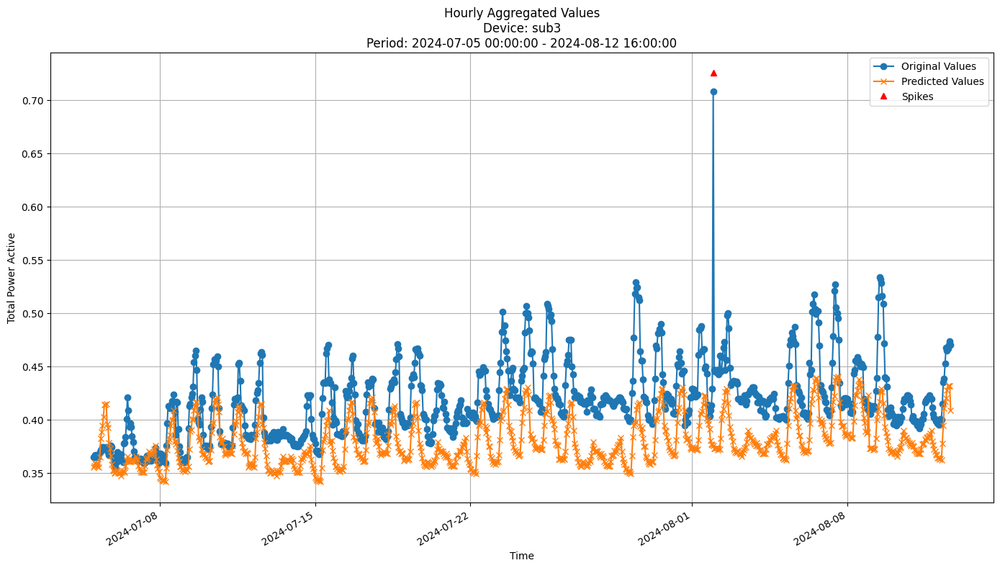


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0444
MAE: 0.0383
MAPE: 8.9242%

Directional Metrics:
Directional Accuracy: 63.6853%
First-Diff Correlation: 0.3261

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


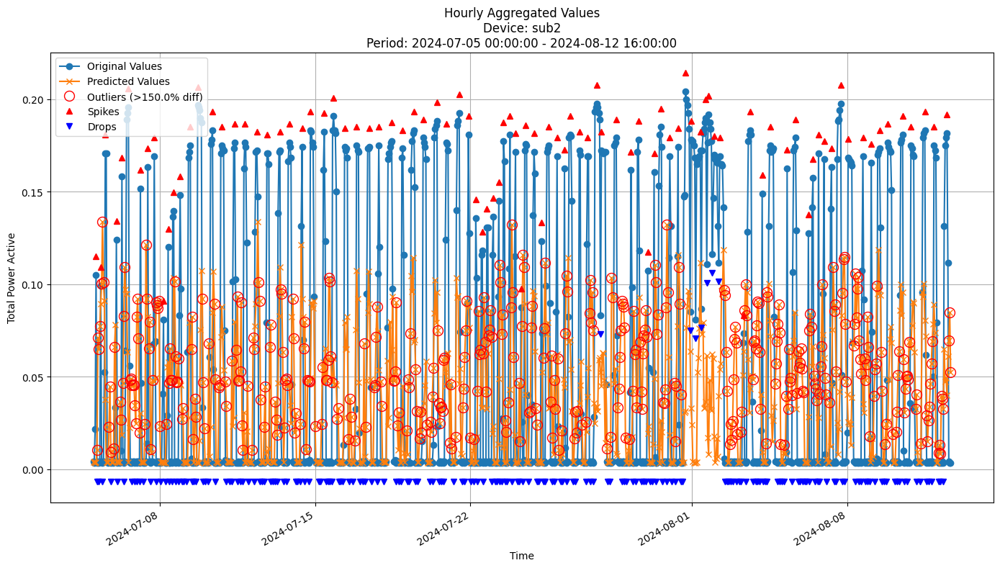


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0764
MAE: 0.0589
MAPE: 598.7551%

Directional Metrics:
Directional Accuracy: 49.1379%
First-Diff Correlation: 0.0108

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


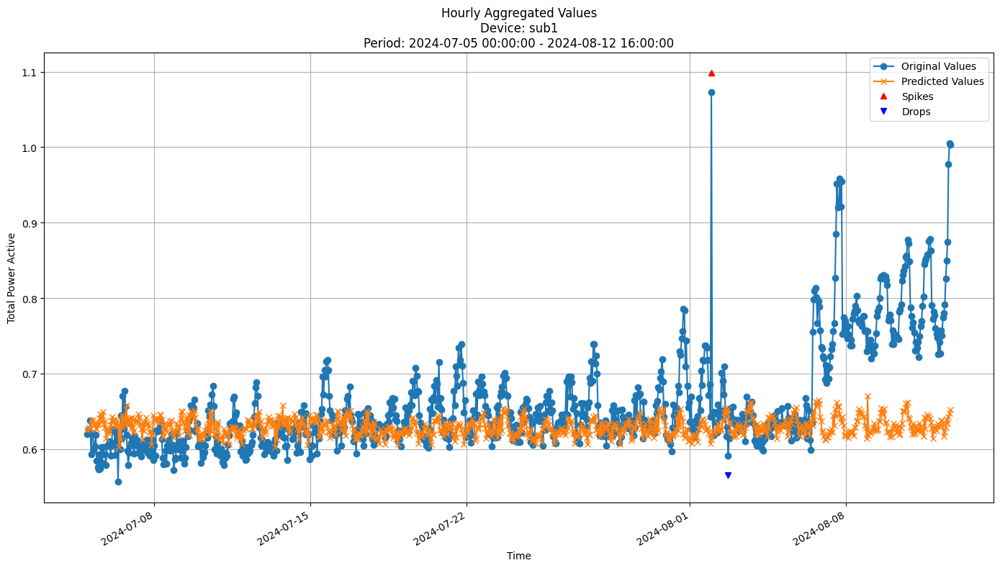


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0738
MAE: 0.0461
MAPE: 6.3518%

Directional Metrics:
Directional Accuracy: 50.4310%
First-Diff Correlation: 0.0853

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [11]:
join_periods = [-2, -1]
# Device iteration
for device_id in bl_mean_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, bl_mean_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, bl_mean_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5,
                            )

### Baseline model (predict previous value)

In [12]:
update_freq = "1h"
bl_prev = PreviousValueRegressor
bl_prev_params = {}

In [13]:
bl_prev_train_period_predictions, bl_prev_valid_period_predictions,\
bl_prev_train_period_metrics, bl_prev_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=bl_prev,
    model_params=bl_prev_params,
    train=train,
    valid=valid,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    verbose=1
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-07-04 23:45:00+02:00
Model's memory usage: 0.000420 MB
Metrics for Device: sub3 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:45:00+02:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0237
	MAE: 0.0077
	MAPE: 1.7684%

Directional Metrics:
	Directional Accuracy: 12.3558%
	First-Diff Correlation: 0.0074

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.1200
		Recall: 0.0938
		F1: 0.1053

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.1304
		Recall: 0.0938
		F1: 0.1091
	Drops:
		Precision: 0.1600
		Recall: 0.1250
		F1: 0.1404
--------------------------------------------------
Hourly Metrics:
-----------------------------------------

Processing devices in split 1:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-08-01 23:45:00+02:00
Model's memory usage: 0.000397 MB
Metrics for Device: sub3 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 16:00:00+02:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0123
	MAE: 0.0072
	MAPE: 1.6425%

Directional Metrics:
	Directional Accuracy: 10.4492%
	First-Diff Correlation: -0.1195

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2857
		Recall: 0.1333
		F1: 0.1818
	Drops:
		Precision: 0.3000
		Recall: 0.1667
		F1: 0.2143

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.5714
		Recall: 0.2667
		F1: 0.3636
	Drops:
		Precision: 0.5000
		Recall: 0.2778
		F1: 0.3571
--------------------------------------------------
Hourly Metrics:
----------------------------------------

#### Results

In [14]:
print("\n\nValid period metrics:")
bl_prev_all_time_valid_metrics = all_time_aggregation_metrics(bl_prev_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Valid period metrics:


Aggregated Metrics Across Periods
Device ID: sub3
--------------------------------------------------
15min Metrics:
	RMSE: 0.0180 ± 0.0057
	MAE: 0.0075 ± 0.0002
	MAPE: 1.7054% ± 0.0630%

	Directional Metrics:
		Directional Accuracy: 11.4025% ± 0.9533%
		First-Diff Correlation: -0.0561 ± 0.0634

	Immediate Detection (delta=0):
		Spike Precision: 0.1429 ± 0.1429
		Spike Recall: 0.0667 ± 0.0667
		Spike F1: 0.0909 ± 0.0909
		Drop Precision: 0.2100 ± 0.0900
		Drop Recall: 0.1302 ± 0.0365
		Drop F1: 0.1598 ± 0.0545

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.3509 ± 0.2205
		Spike Recall: 0.1802 ± 0.0865
		Spike F1: 0.2364 ± 0.1273
		Drop Precision: 0.3300 ± 0.1700
		Drop Recall: 0.2014 ± 0.0764
		Drop F1: 0.2487 ± 0.1084
Hourly Metrics:
	RMSE: 0.0123 ± 0.0021
	MAE: 0.0066 ± 0.0002
	MAPE: 1.5152% ± 0.0654%

	Directional Metrics:
		Directional Accuracy: 46.6119% ± 0.2631%
		First-Diff Correlation: 0.3853 ± 0.0414

	Immediate Detection (delta=0):
		Spike

#### Validation plots

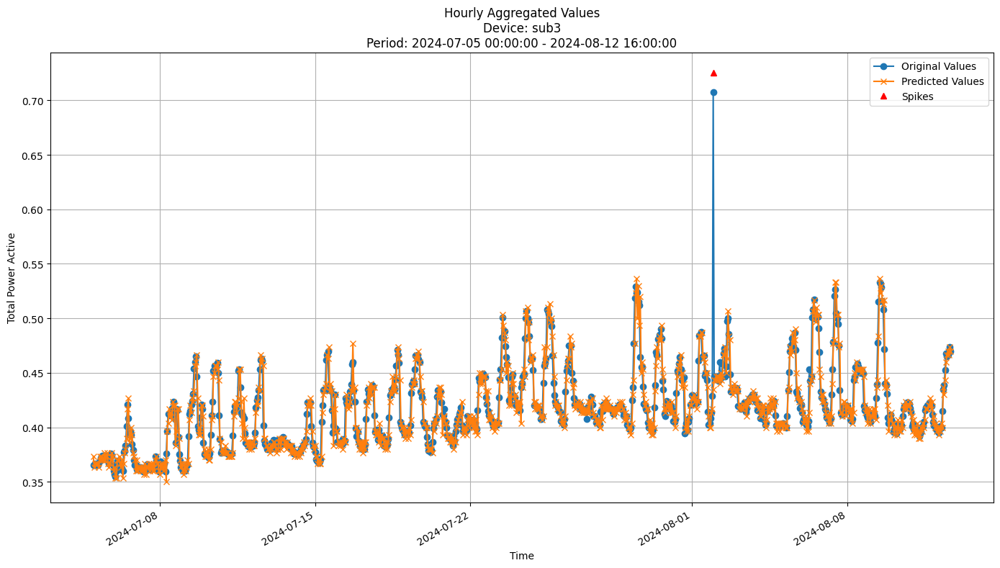


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0134
MAE: 0.0067
MAPE: 1.5445%

Directional Metrics:
Directional Accuracy: 46.4440%
First-Diff Correlation: 0.3013

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


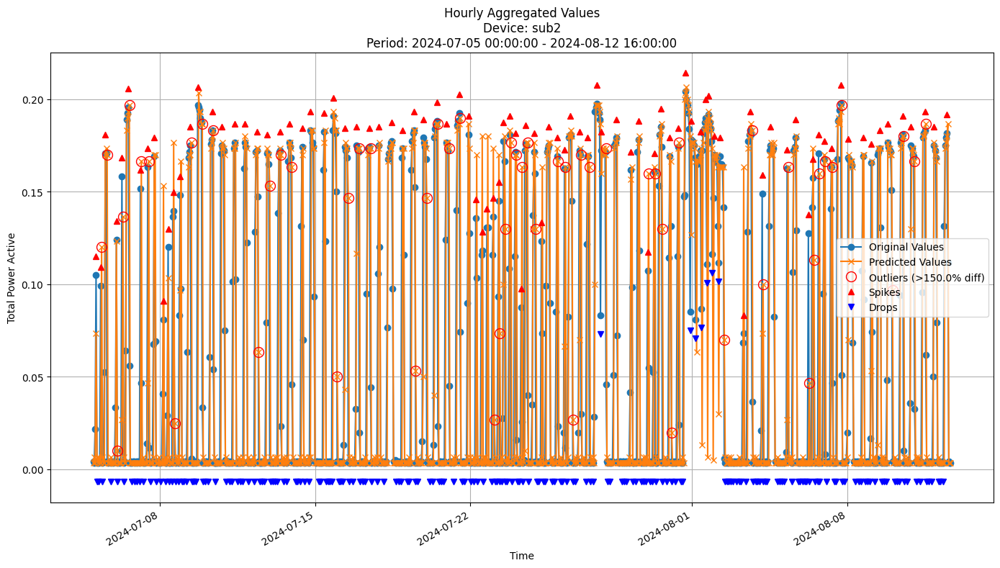


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0511
MAE: 0.0231
MAPE: 123.7885%

Directional Metrics:
Directional Accuracy: 36.8534%
First-Diff Correlation: 0.3519

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


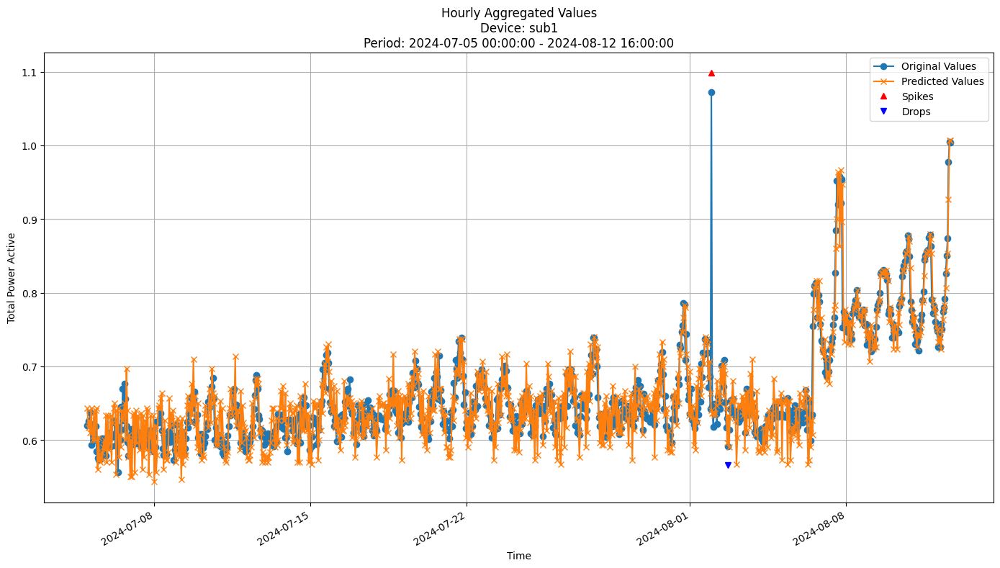


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0335
MAE: 0.0242
MAPE: 3.7193%

Directional Metrics:
Directional Accuracy: 42.7802%
First-Diff Correlation: -0.1220

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [15]:
join_periods = [-2, -1]
# Device iteration
for device_id in bl_prev_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, bl_prev_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, bl_prev_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5,
                            )

### GBDT

In [16]:
update_freq = "14D"  # Update the model every 14 days

gbdt = GradientBoostingRegressor
gbdt_params ={
    'n_estimators': 150, 
    'learning_rate': 0.01, 
    'max_depth': 3, 
    'subsample': 0.8, 
    'random_state': 42
    }

In [17]:
gbdt_train_period_predictions, gbdt_valid_period_predictions, \
gbdt_train_period_metrics, gbdt_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=gbdt, 
    model_params=gbdt_params, 
    train=train, 
    valid=valid, 
    incremental=False,
    data_freq=DATA_FREQUENCY, 
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]


Retraining model on data from 2024-06-07 00:00:00+02:00 to 2024-07-04 23:45:00+02:00

Time: 0.22 seconds
Predicting for chunk from 2024-07-05 00:00:00+02:00 to 2024-07-19 00:00:00+02:00

-------------------------

Retraining model on data from 2024-06-07 00:00:00+02:00 to 2024-07-19 00:00:00+02:00

Time: 0.31 seconds
Predicting for chunk from 2024-07-19 00:15:00+02:00 to 2024-08-01 23:45:00+02:00

-------------------------
Model's memory usage: 0.012337 MB
Metrics for Device: sub3 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:45:00+02:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0320
	MAE: 0.0164
	MAPE: 3.6784%

Directional Metrics:
	Directional Accuracy: 52.6982%
	First-Diff Correlation: 0.0390

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0294
		Recall: 0.0312
		F1: 0.0303
	Drops:
		Precision: 0.0385
		Recall: 0.0312
		F1: 0.0345

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spik

Processing devices in split 1:   0%|          | 0/3 [00:00<?, ?it/s]


Retraining model on data from 2024-06-07 00:00:00+02:00 to 2024-08-01 23:45:00+02:00

Time: 0.41 seconds
Predicting for chunk from 2024-08-02 00:00:00+02:00 to 2024-08-12 16:00:00+02:00

-------------------------
Model's memory usage: 0.012146 MB
Metrics for Device: sub3 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 16:00:00+02:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0214
	MAE: 0.0166
	MAPE: 3.7418%

Directional Metrics:
	Directional Accuracy: 54.8828%
	First-Diff Correlation: 0.2369

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0606
		Recall: 0.1333
		F1: 0.0833
	Drops:
		Precision: 0.0312
		Recall: 0.0556
		F1: 0.0400

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.1212
		Recall: 0.2667
		F1: 0.1667
	Drops:
		Precision: 0.0312
		Recall: 0.0556
		F1: 0.0400
--------------------------------------------------
Hourly Metrics:
-----------------------------------

#### Results

In [18]:
print("\n\nTrain period metrics:")
gbdt_all_time_train_metrics = all_time_aggregation_metrics(gbdt_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
gbdt_all_time_valid_metrics = all_time_aggregation_metrics(gbdt_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
# Hourly Metrics:
# 	RMSE: 0.2486 ± 0.0612
# 	MAE: 0.1594 ± 0.0516
# 	MAPE: 33.4958% ± 5.3587%

# 	Directional Metrics:
# 		Directional Accuracy: 62.4754% ± 7.1041%
# 		First-Diff Correlation: 0.3821 ± 0.0970

# 	Immediate Detection (delta=0):
# 		Spike Precision: 0.1544 ± 0.1193
# 		Spike Recall: 0.1617 ± 0.1297
# 		Spike F1: 0.1577 ± 0.1238
# 		Drop Precision: 0.1459 ± 0.0857
# 		Drop Recall: 0.1534 ± 0.0909
# 		Drop F1: 0.1493 ± 0.0879

# 	1-Hour Delayed Detection (delta=1):
# 		Spike Precision: 0.4691 ± 0.2714
# 		Spike Recall: 0.4908 ± 0.2907
# 		Spike F1: 0.4788 ± 0.2795
# 		Drop Precision: 0.2117 ± 0.1062
# 		Drop Recall: 0.2201 ± 0.1161
# 		Drop F1: 0.2153 ± 0.1100



Train period metrics:


Aggregated Metrics Across Periods
Device ID: sub3
--------------------------------------------------
15min Metrics:
	RMSE: 0.0176 ± 0.0040
	MAE: 0.0110 ± 0.0009
	MAPE: 2.8283% ± 0.1539%

	Directional Metrics:
		Directional Accuracy: 53.4654% ± 0.8788%
		First-Diff Correlation: 0.1068 ± 0.0362

	Immediate Detection (delta=0):
		Spike Precision: 0.0208 ± 0.0208
		Spike Recall: 0.0161 ± 0.0161
		Spike F1: 0.0182 ± 0.0182
		Drop Precision: 0.0799 ± 0.0222
		Drop Recall: 0.0509 ± 0.0047
		Drop F1: 0.0616 ± 0.0103

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.1537 ± 0.0338
		Spike Recall: 0.1092 ± 0.0360
		Spike F1: 0.1273 ± 0.0364
		Drop Precision: 0.1580 ± 0.0151
		Drop Recall: 0.1081 ± 0.0303
		Drop F1: 0.1273 ± 0.0266
Hourly Metrics:
	RMSE: 0.0142 ± 0.0020
	MAE: 0.0101 ± 0.0010
	MAPE: 2.6054% ± 0.1853%

	Directional Metrics:
		Directional Accuracy: 58.5474% ± 0.1272%
		First-Diff Correlation: 0.2581 ± 0.0391

	Immediate Detection (delta=0):
		Spike 

#### Training plots

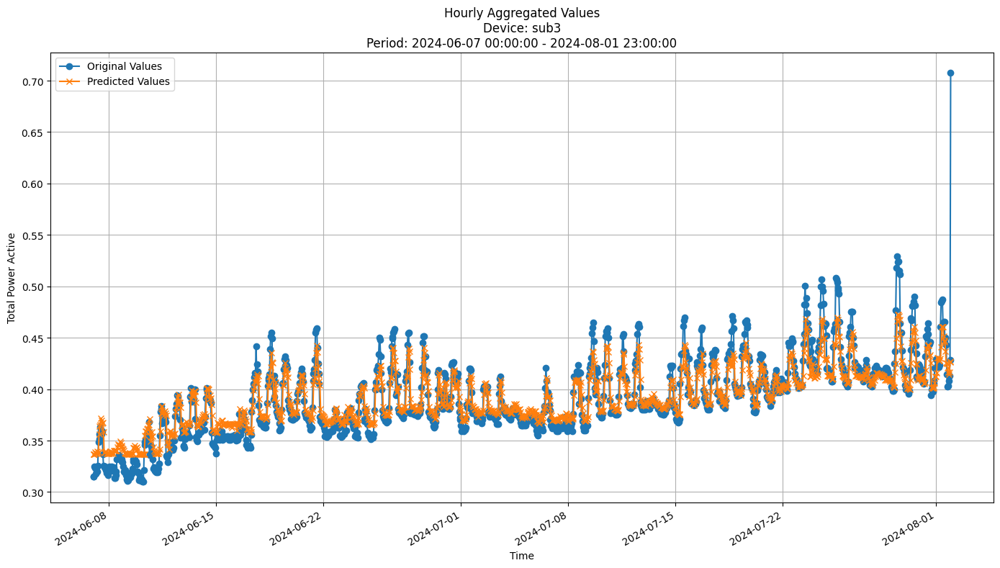


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0163
MAE: 0.0111
MAPE: 2.7907%

Directional Metrics:
Directional Accuracy: 58.6746%
First-Diff Correlation: 0.2190

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


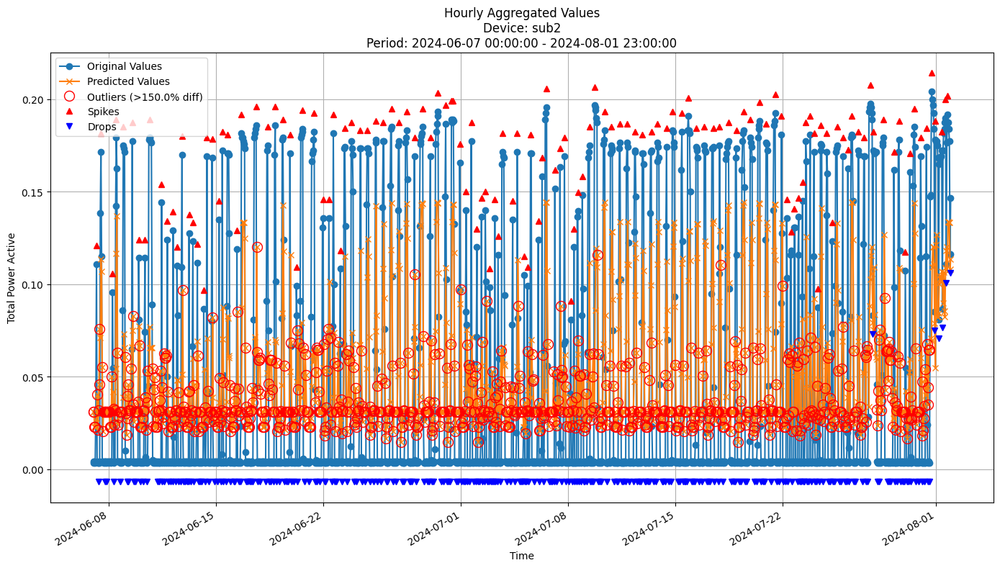


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0527
MAE: 0.0433
MAPE: 548.9352%

Directional Metrics:
Directional Accuracy: 49.1437%
First-Diff Correlation: 0.2905

Immediate Detection (delta=0):
Spikes:
  Precision: 0.3800
  Recall: 0.1387
  F1 Score: 0.2032
Drops:
  Precision: 0.3400
  Recall: 0.0637
  F1 Score: 0.1073

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8600
  Recall: 0.3139
  F1 Score: 0.4599
Drops:
  Precision: 0.8600
  Recall: 0.1610
  F1 Score: 0.2713


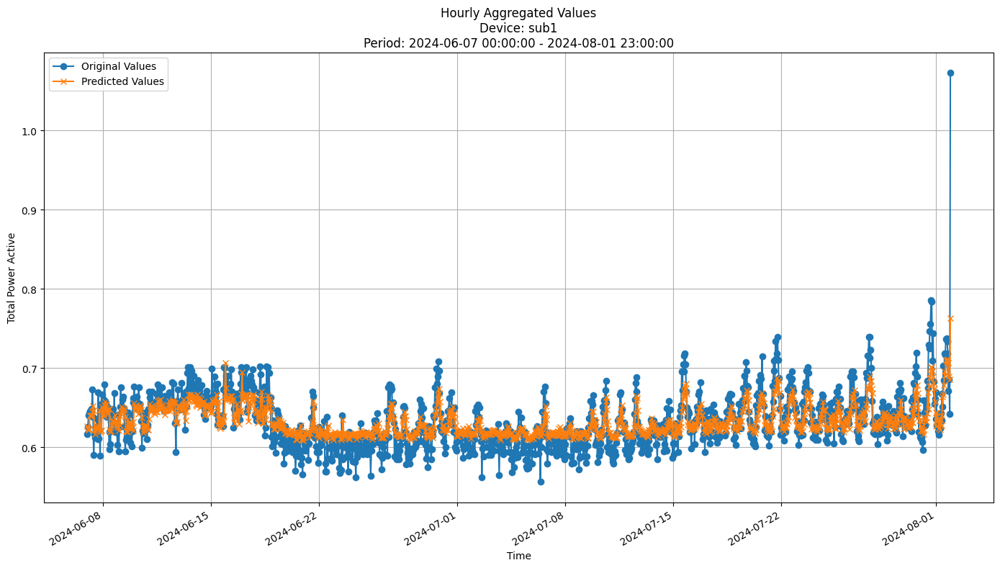


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0225
MAE: 0.0166
MAPE: 2.6039%

Directional Metrics:
Directional Accuracy: 54.2070%
First-Diff Correlation: 0.1823

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [19]:
for device_id in gbdt_train_period_predictions.keys():
    y_train = gbdt_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = gbdt_train_period_predictions[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)
# 0.17, 0.12, 25.55, 70.81%, 0.72

#### Validation plots
Plot only the last few periods of predictions

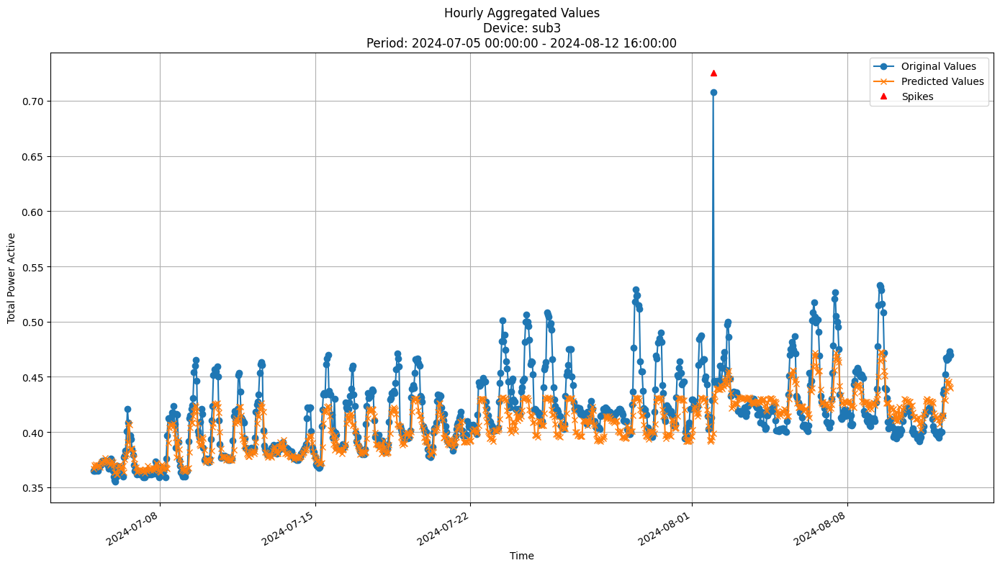


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0243
MAE: 0.0157
MAPE: 3.5393%

Directional Metrics:
Directional Accuracy: 59.0517%
First-Diff Correlation: 0.1024

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


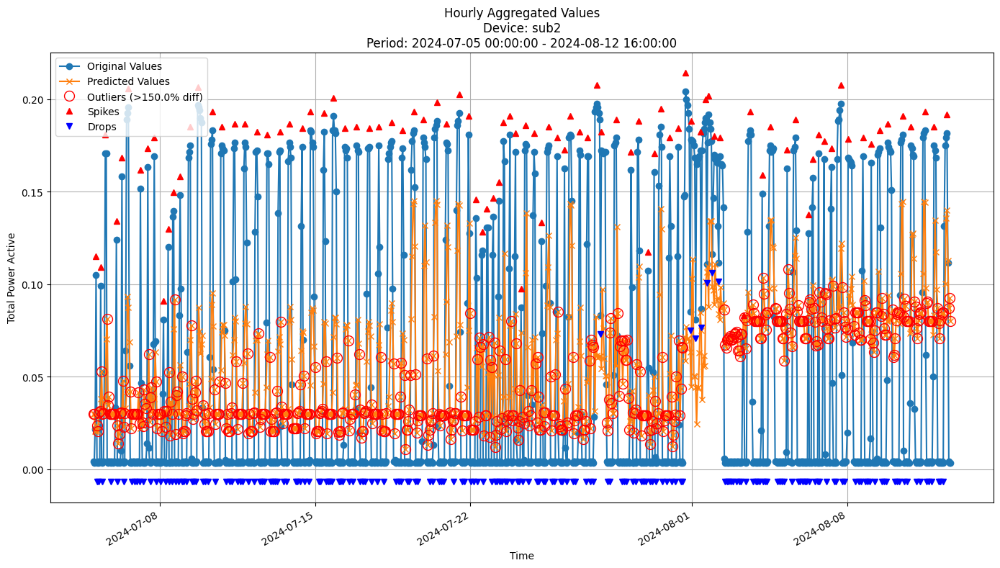


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0639
MAE: 0.0541
MAPE: 701.2596%

Directional Metrics:
Directional Accuracy: 50.6466%
First-Diff Correlation: 0.2435

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


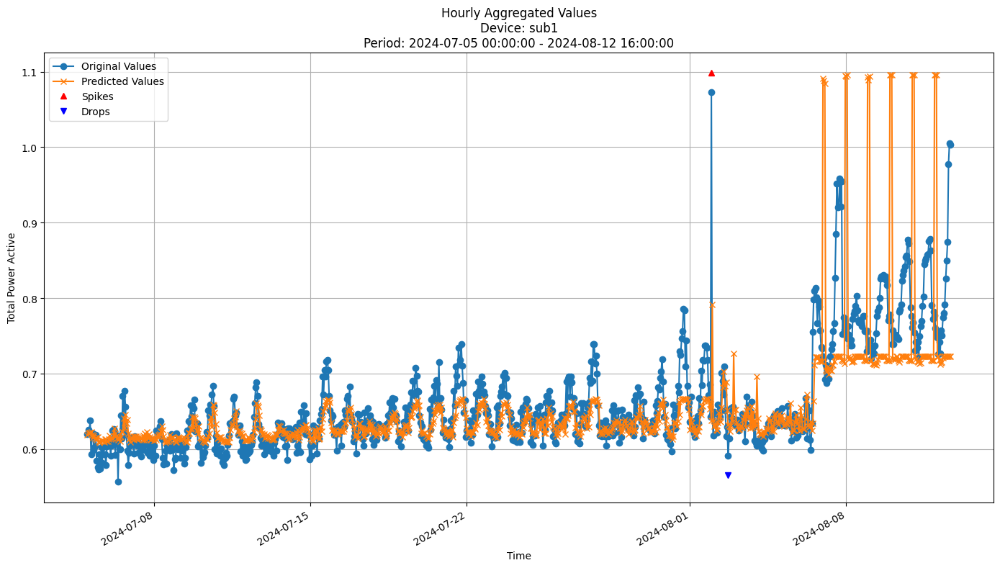


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0656
MAE: 0.0323
MAPE: 4.4474%

Directional Metrics:
Directional Accuracy: 50.2155%
First-Diff Correlation: -0.0501

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.1429
  Recall: 1.0000
  F1 Score: 0.2500
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [20]:
join_periods = [-1, -2]
# Device iteration
for device_id in gbdt_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, gbdt_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, gbdt_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

# Basic Prediction Metrics:
# RMSE: 0.2195
# MAE: 0.1398
# MAPE: 33.6987%

### Random Forest model

In [21]:
update_freq = "14D"  # Update the model every 14 days
rf = RandomForestRegressor
rf_params = {'n_estimators': 300, 
             'max_depth': 7, 
             'max_features': 1.0, 
             'random_state': 42, 
             'n_jobs': -1}

In [22]:

rf_train_period_predictions, rf_valid_period_predictions, \
rf_train_period_metrics, rf_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=rf, 
    model_params=rf_params, 
    train=train, 
    valid=valid, 
    incremental=False,
    data_freq=DATA_FREQUENCY, 
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]


Retraining model on data from 2024-06-07 00:00:00+02:00 to 2024-07-04 23:45:00+02:00

Time: 0.42 seconds
Predicting for chunk from 2024-07-05 00:00:00+02:00 to 2024-07-19 00:00:00+02:00

-------------------------

Retraining model on data from 2024-06-07 00:00:00+02:00 to 2024-07-19 00:00:00+02:00

Time: 0.42 seconds
Predicting for chunk from 2024-07-19 00:15:00+02:00 to 2024-08-01 23:45:00+02:00

-------------------------
Model's memory usage: 0.119888 MB
Metrics for Device: sub3 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:45:00+02:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0282
	MAE: 0.0130
	MAPE: 2.9592%

Directional Metrics:
	Directional Accuracy: 56.2709%
	First-Diff Correlation: 0.0309

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0500
		Recall: 0.0312
		F1: 0.0385

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spik

Processing devices in split 1:   0%|          | 0/3 [00:00<?, ?it/s]


Retraining model on data from 2024-06-07 00:00:00+02:00 to 2024-08-01 23:45:00+02:00

Time: 0.34 seconds
Predicting for chunk from 2024-08-02 00:00:00+02:00 to 2024-08-12 16:00:00+02:00

-------------------------
Model's memory usage: 0.119881 MB
Metrics for Device: sub3 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 16:00:00+02:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1006
	MAE: 0.0507
	MAPE: 12.1219%

Directional Metrics:
	Directional Accuracy: 57.2266%
	First-Diff Correlation: 0.1031

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0533
		Recall: 0.2222
		F1: 0.0860

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0667
		Recall: 0.2778
		F1: 0.1075
--------------------------------------------------
Hourly Metrics:
----------------------------------

#### Results

In [23]:
print("\n\nTrain period metrics:")
rf_all_time_train_metrics = all_time_aggregation_metrics(rf_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
rf_all_time_valid_metrics = all_time_aggregation_metrics(rf_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)

# Best values:
# Hourly Metrics:
# 	RMSE: 0.2221 ± 0.0148
# 	MAE: 0.1267 ± 0.0092
# 	MAPE: 22.1472% ± 2.0063%

# 	Directional Metrics:
# 		Directional Accuracy: 60.8511% ± 2.9815%
# 		First-Diff Correlation: 0.4859 ± 0.0565

# 	Immediate Detection (delta=0):
# 		Spike Precision: 0.2094 ± 0.0638
# 		Spike Recall: 0.1844 ± 0.0780
# 		Spike F1: 0.1927 ± 0.0741
# 		Drop Precision: 0.0547 ± 0.0125
# 		Drop Recall: 0.1408 ± 0.0536
# 		Drop F1: 0.0779 ± 0.0216

# 	1-Hour Delayed Detection (delta=1):
# 		Spike Precision: 0.4647 ± 0.0473
# 		Spike Recall: 0.3984 ± 0.1023
# 		Spike F1: 0.4191 ± 0.0799
# 		Drop Precision: 0.1104 ± 0.0172
# 		Drop Recall: 0.2821 ± 0.0884
# 		Drop F1: 0.1571 ± 0.0324



Train period metrics:


Aggregated Metrics Across Periods
Device ID: sub3
--------------------------------------------------
15min Metrics:
	RMSE: 0.0103 ± 0.0018
	MAE: 0.0066 ± 0.0007
	MAPE: 1.6905% ± 0.1194%

	Directional Metrics:
		Directional Accuracy: 62.3408% ± 1.0385%
		First-Diff Correlation: 0.6193 ± 0.2513

	Immediate Detection (delta=0):
		Spike Precision: 0.1563 ± 0.0611
		Spike Recall: 0.0932 ± 0.0287
		Spike F1: 0.1166 ± 0.0397
		Drop Precision: 0.1030 ± 0.0160
		Drop Recall: 0.0432 ± 0.0124
		Drop F1: 0.0606 ± 0.0152

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2614 ± 0.0005
		Spike Recall: 0.1619 ± 0.0155
		Spike F1: 0.1995 ± 0.0120
		Drop Precision: 0.1724 ± 0.0419
		Drop Recall: 0.0731 ± 0.0269
		Drop F1: 0.1023 ± 0.0341
Hourly Metrics:
	RMSE: 0.0076 ± 0.0010
	MAE: 0.0052 ± 0.0006
	MAPE: 1.3189% ± 0.1093%

	Directional Metrics:
		Directional Accuracy: 65.7358% ± 0.5831%
		First-Diff Correlation: 0.6332 ± 0.0184

	Immediate Detection (delta=0):
		Spike 

#### Training plots
Plot only the last period of predictions

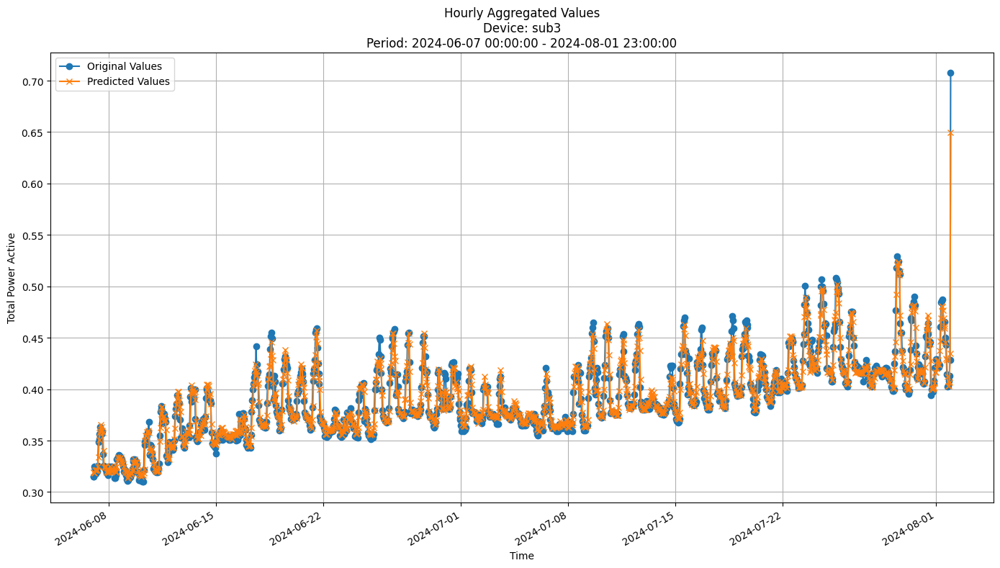


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0086
MAE: 0.0057
MAPE: 1.4282%

Directional Metrics:
Directional Accuracy: 65.1526%
First-Diff Correlation: 0.6516

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


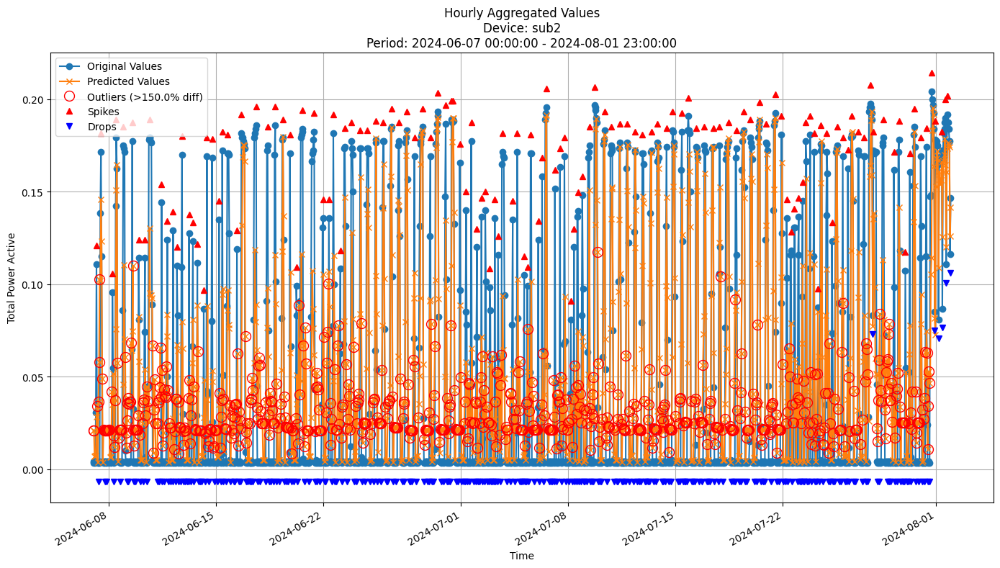


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0428
MAE: 0.0303
MAPE: 375.8453%

Directional Metrics:
Directional Accuracy: 61.9509%
First-Diff Correlation: 0.4848

Immediate Detection (delta=0):
Spikes:
  Precision: 0.6364
  Recall: 0.0511
  F1 Score: 0.0946
Drops:
  Precision: 0.3636
  Recall: 0.0150
  F1 Score: 0.0288

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8182
  Recall: 0.0657
  F1 Score: 0.1216
Drops:
  Precision: 0.8182
  Recall: 0.0337
  F1 Score: 0.0647


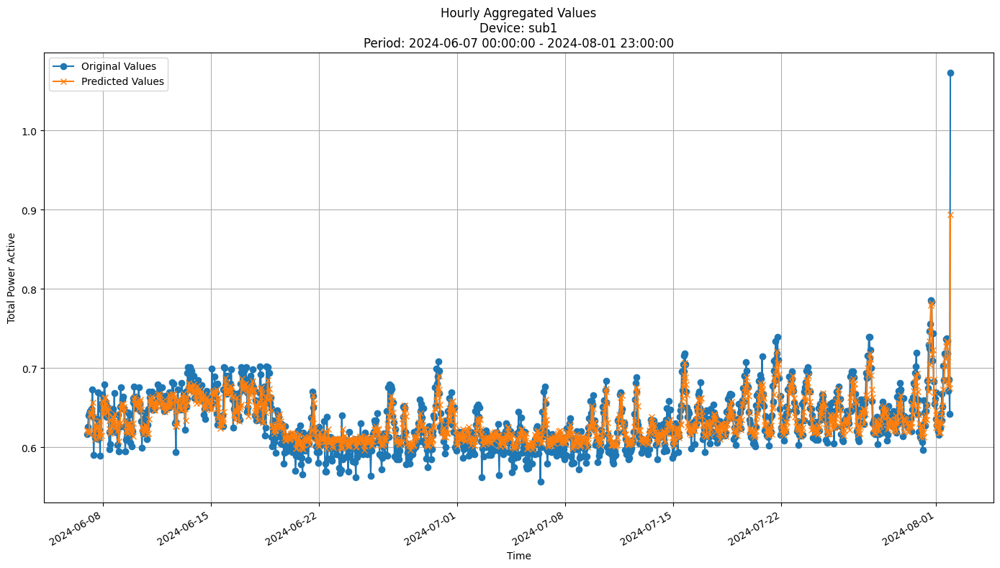


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0171
MAE: 0.0127
MAPE: 1.9991%

Directional Metrics:
Directional Accuracy: 58.8980%
First-Diff Correlation: 0.4426

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [24]:
for device_id in rf_train_period_predictions.keys():
    y_train = rf_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = rf_train_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last periods of predictions

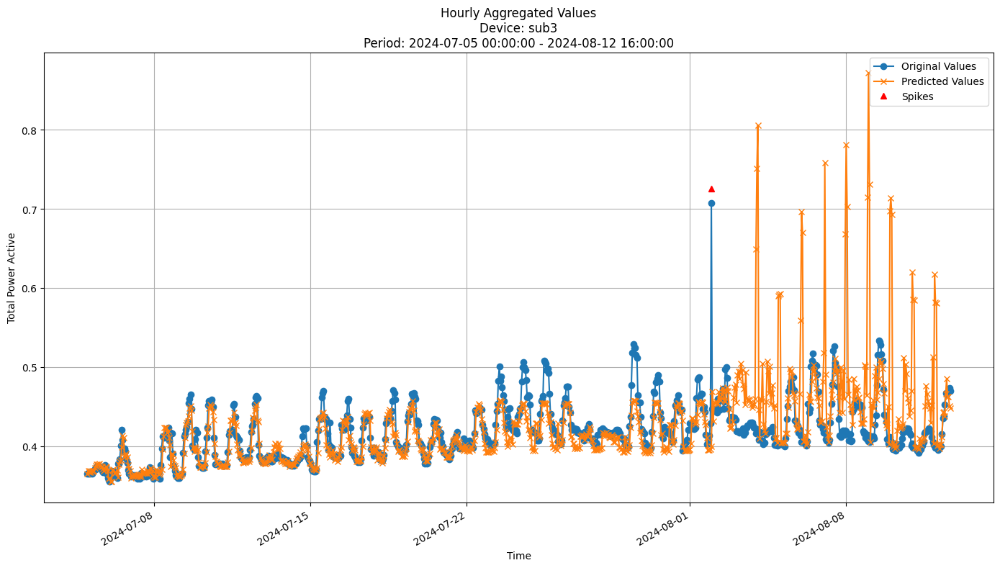


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0516
MAE: 0.0222
MAPE: 5.2170%

Directional Metrics:
Directional Accuracy: 59.1595%
First-Diff Correlation: 0.0250

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


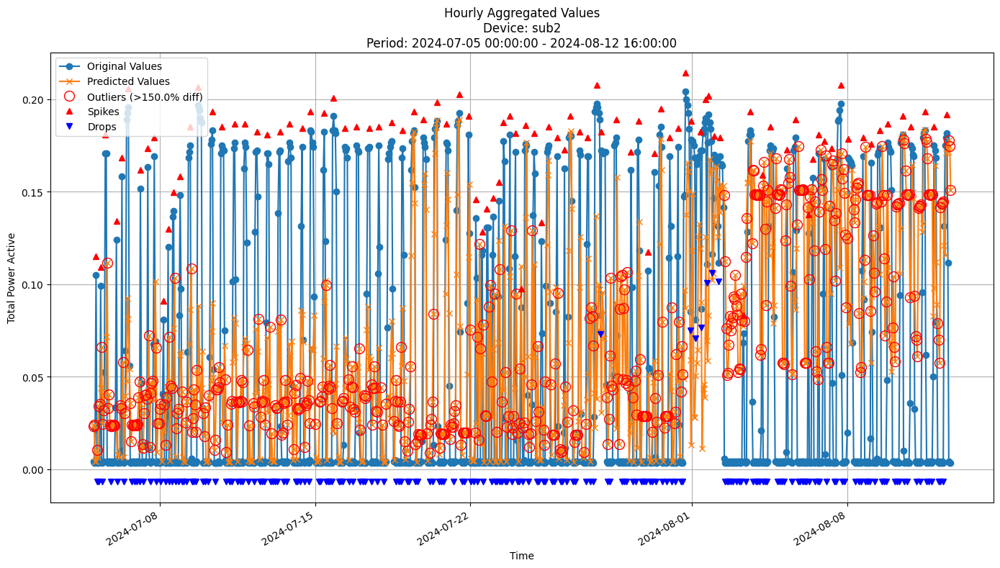


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0756
MAE: 0.0574
MAPE: 864.1590%

Directional Metrics:
Directional Accuracy: 55.1724%
First-Diff Correlation: 0.1523

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


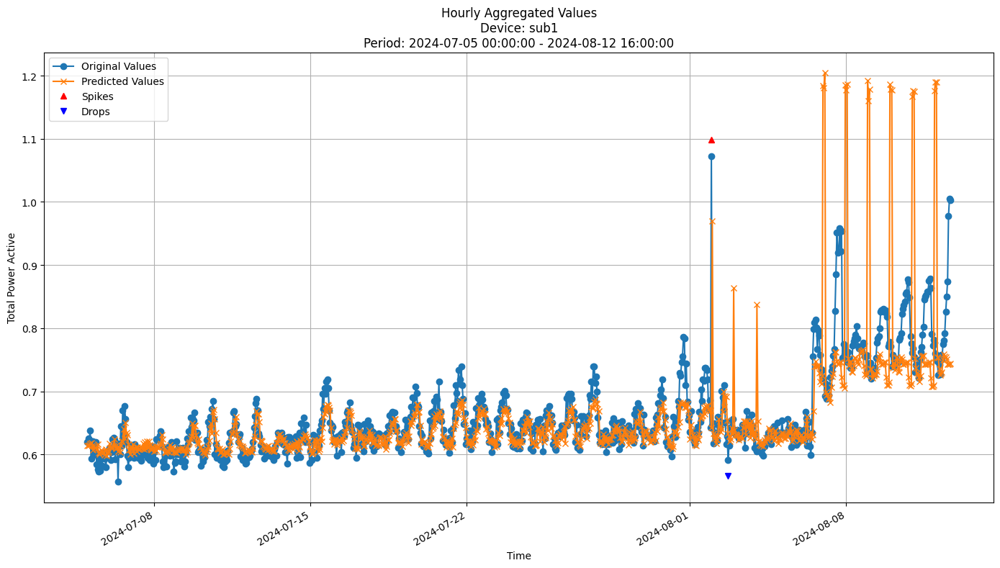


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0734
MAE: 0.0310
MAPE: 4.2766%

Directional Metrics:
Directional Accuracy: 53.5560%
First-Diff Correlation: -0.0844

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.1111
  Recall: 1.0000
  F1 Score: 0.2000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [25]:
join_periods = [-1, -2]
# Device iteration
for device_id in rf_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, rf_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, rf_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### Hoeffding Tree

In [26]:
update_freq = "15min"  # for incremental models put the same as the data frequency to recreate real world scenario

hoef = HoeffdingTreeRegressor
hoef_params = {'max_depth': 10,
               'grace_period': 96,
               'tau': 0.001,
               'delta': 0.005}

In [27]:

hoef_all_train_preds, hoef_all_valid_preds, \
hoef_all_train_metrics, hoef_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=hoef, 
    model_params=hoef_params, 
    train=train, 
    valid=valid, 
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-07-04 23:45:00+02:00
Model's memory usage: 0.016861 MB
Metrics for Device: sub3 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:45:00+02:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0529
	MAE: 0.0377
	MAPE: 8.5737%

Directional Metrics:
	Directional Accuracy: 16.6729%
	First-Diff Correlation: 0.0163

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Hourly Metrics:
-----------------------------------------

Processing devices in split 1:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-08-01 23:45:00+02:00
Model's memory usage: 0.033958 MB
Metrics for Device: sub3 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 16:00:00+02:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0493
	MAE: 0.0370
	MAPE: 8.1202%

Directional Metrics:
	Directional Accuracy: 16.6992%
	First-Diff Correlation: 0.0065

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Hourly Metrics:
-----------------------------------------

#### Results

In [28]:
print("\n\nTrain period metrics:")
hoef_all_time_train_metrics = all_time_aggregation_metrics(hoef_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
hoef_all_time_valid_metrics = all_time_aggregation_metrics(hoef_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: sub3
--------------------------------------------------
15min Metrics:
	RMSE: 0.0361 ± 0.0050
	MAE: 0.0271 ± 0.0036
	MAPE: 7.1042% ± 0.7310%

	Directional Metrics:
		Directional Accuracy: 7.8054% ± 0.2132%
		First-Diff Correlation: 0.0300 ± 0.0178

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000
Hourly Metrics:
	RMSE: 0.0346 ± 0.0040
	MAE: 0.0268 ± 0.0036
	MAPE: 7.0234% ± 0.7533%

	Directional Metrics:
		Directional Accuracy: 3.4639% ± 0.5599%
		First-Diff Correlation: 0.0587 ± 0.0182

	Immediate Detection (delta=0):
		Spike Pr

#### Training plots
Plot only the last period of predictions

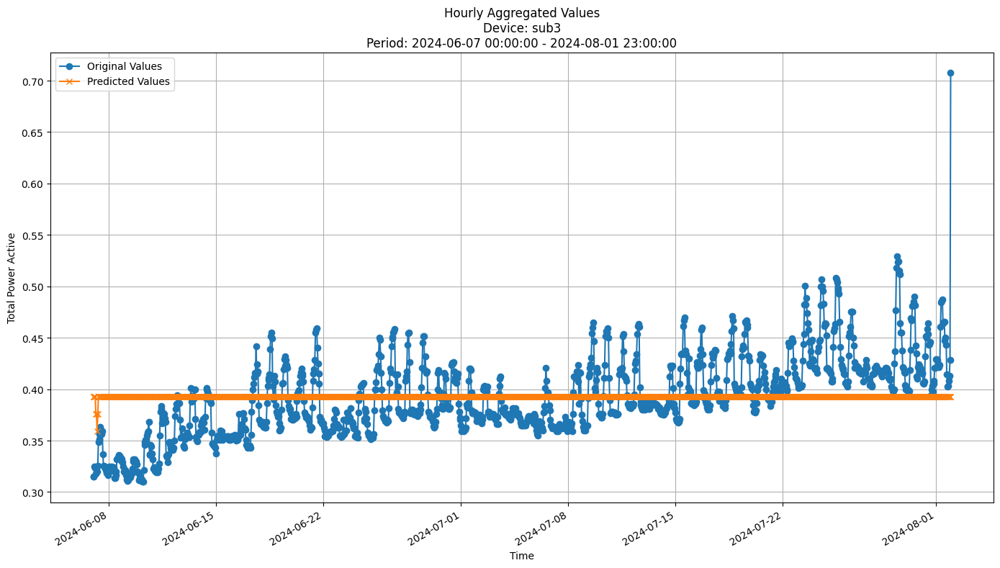


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0386
MAE: 0.0304
MAPE: 7.7767%

Directional Metrics:
Directional Accuracy: 2.9039%
First-Diff Correlation: 0.0405

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


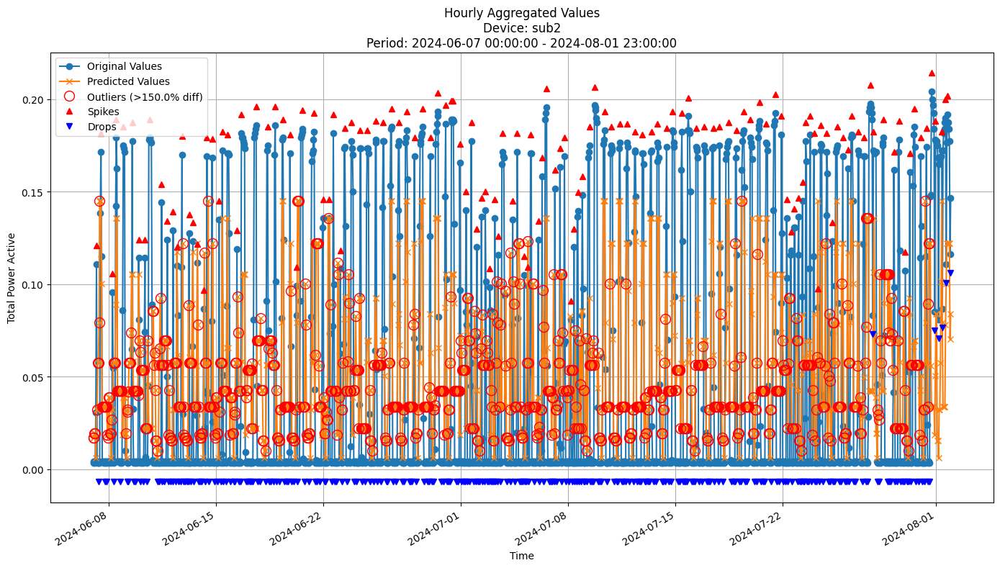


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0618
MAE: 0.0494
MAPE: 679.2861%

Directional Metrics:
Directional Accuracy: 33.5815%
First-Diff Correlation: 0.3381

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


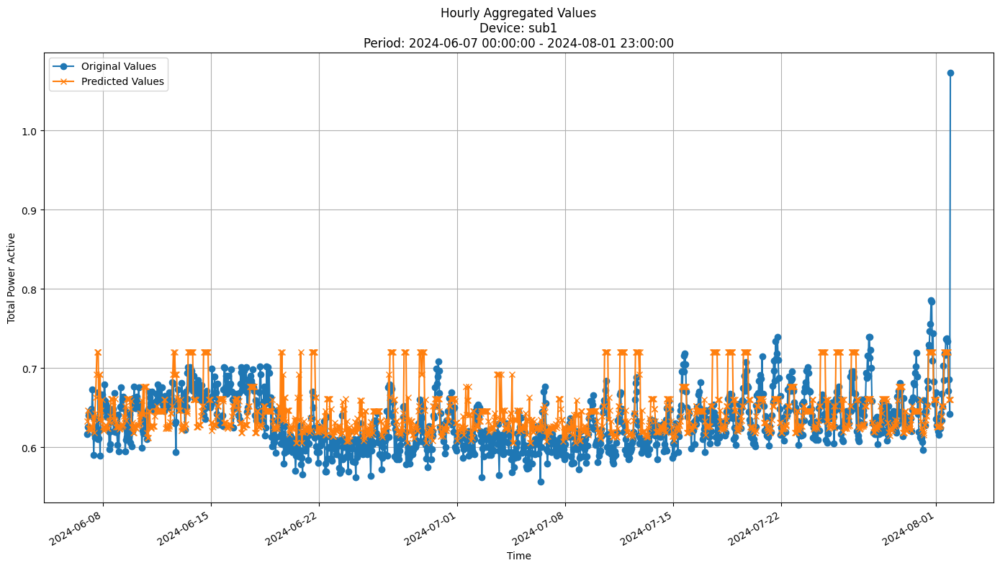


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0381
MAE: 0.0285
MAPE: 4.5052%

Directional Metrics:
Directional Accuracy: 28.1459%
First-Diff Correlation: -0.0119

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [29]:
for device_id in hoef_all_train_preds.keys():
    y_train = hoef_all_train_preds[device_id][-1]['y_true']
    y_pred_train = hoef_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

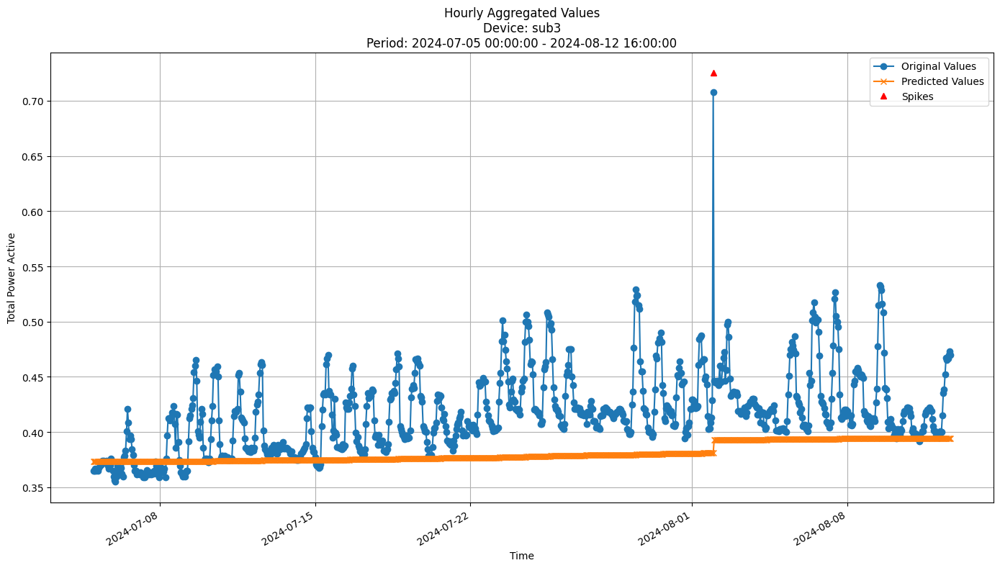


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0493
MAE: 0.0374
MAPE: 8.4573%

Directional Metrics:
Directional Accuracy: 46.1207%
First-Diff Correlation: -0.5066

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


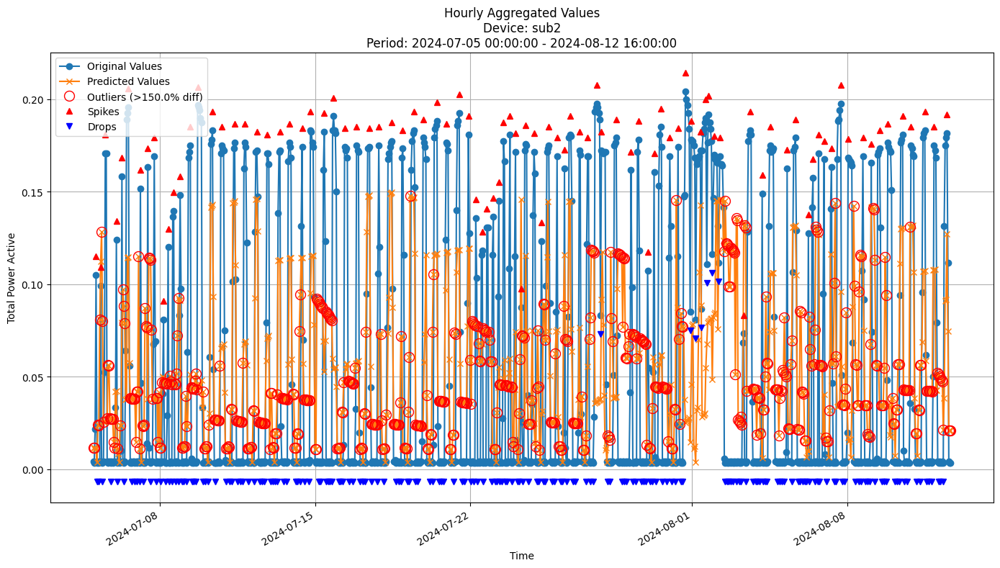


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0694
MAE: 0.0550
MAPE: 687.4921%

Directional Metrics:
Directional Accuracy: 52.9095%
First-Diff Correlation: 0.3034

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


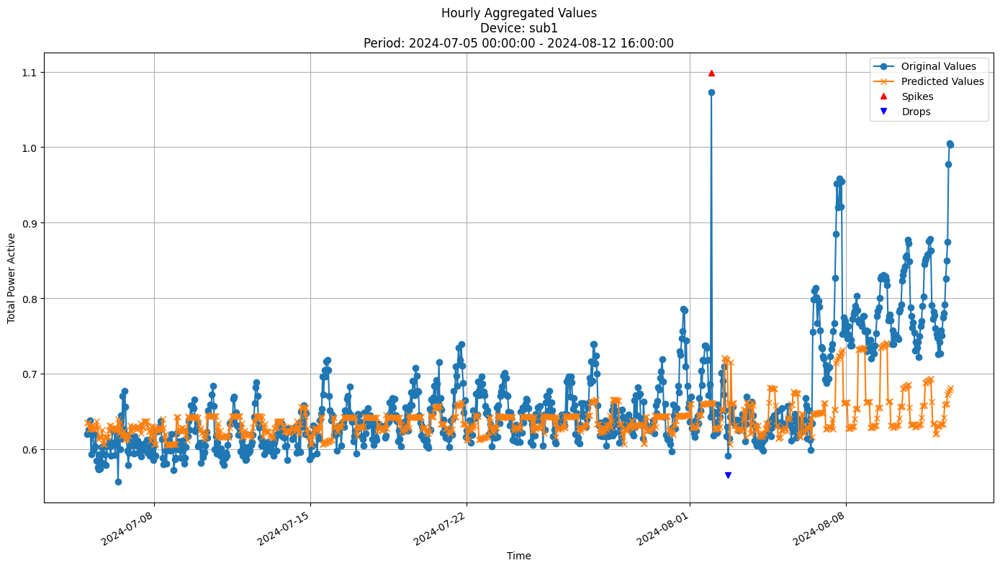


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0625
MAE: 0.0395
MAPE: 5.4729%

Directional Metrics:
Directional Accuracy: 46.4440%
First-Diff Correlation: 0.0327

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [30]:
join_periods = [-1, -2]
# Device iteration
for device_id in hoef_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, hoef_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, hoef_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (Hoeffding Tree)

In [31]:
update_freq = "15min"  # for incremental models put the same as the data frequency to recreate real world scenario

arf_hf = ARFRegressor
arf_hf_params = {
    'n_models': 12,
    'max_features': 0.8,
    'aggregation_method': 'median',
    'grace_period': 10,
    'max_depth': 10,
    'delta': 0.5,  # split confidence
    'tau': 0.01,  # break ties
    'seed': 42
}


In [32]:

arf_hf_all_train_preds, arf_hf_all_valid_preds, \
arf_hf_all_train_metrics, arf_hf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=arf_hf,
    model_params=arf_hf_params,
    train=train,
    valid=valid,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-07-04 23:45:00+02:00
Model's memory usage: 2.248146 MB
Metrics for Device: sub3 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:45:00+02:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0443
	MAE: 0.0318
	MAPE: 7.3199%

Directional Metrics:
	Directional Accuracy: 18.9058%
	First-Diff Correlation: -0.0001

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0714
		Recall: 0.0625
		F1: 0.0667
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.1786
		Recall: 0.1562
		F1: 0.1667
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Hourly Metrics:
----------------------------------------

Processing devices in split 1:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-08-01 23:45:00+02:00
Model's memory usage: 3.281403 MB
Metrics for Device: sub3 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 16:00:00+02:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0230
	MAE: 0.0174
	MAPE: 3.9536%

Directional Metrics:
	Directional Accuracy: 22.7539%
	First-Diff Correlation: 0.0635

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0667
		Recall: 0.0667
		F1: 0.0667
	Drops:
		Precision: 0.0526
		Recall: 0.0556
		F1: 0.0541

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.2667
		Recall: 0.2667
		F1: 0.2667
	Drops:
		Precision: 0.1053
		Recall: 0.1111
		F1: 0.1081
--------------------------------------------------
Hourly Metrics:
-----------------------------------------

#### Results

In [33]:
print("\n\nTrain period metrics:")
arf_hf_all_time_train_metrics = all_time_aggregation_metrics(arf_hf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_hf_all_time_valid_metrics = all_time_aggregation_metrics(arf_hf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: sub3
--------------------------------------------------
15min Metrics:
	RMSE: 0.0366 ± 0.0104
	MAE: 0.0289 ± 0.0090
	MAPE: 7.8688% ± 2.3440%

	Directional Metrics:
		Directional Accuracy: 19.5366% ± 1.0774%
		First-Diff Correlation: 0.0296 ± 0.0150

	Immediate Detection (delta=0):
		Spike Precision: 0.0332 ± 0.0002
		Spike Recall: 0.0364 ± 0.0120
		Spike F1: 0.0337 ± 0.0055
		Drop Precision: 0.0454 ± 0.0084
		Drop Recall: 0.0355 ± 0.0201
		Drop F1: 0.0382 ± 0.0165

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.1441 ± 0.0892
		Spike Recall: 0.1257 ± 0.0450
		Spike F1: 0.1313 ± 0.0659
		Drop Precision: 0.0962 ± 0.0221
		Drop Recall: 0.0765 ± 0.0457
		Drop F1: 0.0818 ± 0.0384
Hourly Metrics:
	RMSE: 0.0352 ± 0.0096
	MAE: 0.0285 ± 0.0091
	MAPE: 7.7715% ± 2.3607%

	Directional Metrics:
		Directional Accuracy: 55.1589% ± 1.7710%
		First-Diff Correlation: 0.3534 ± 0.0624

	Immediate Detection (delta=0):
		Spike 

#### Training plots

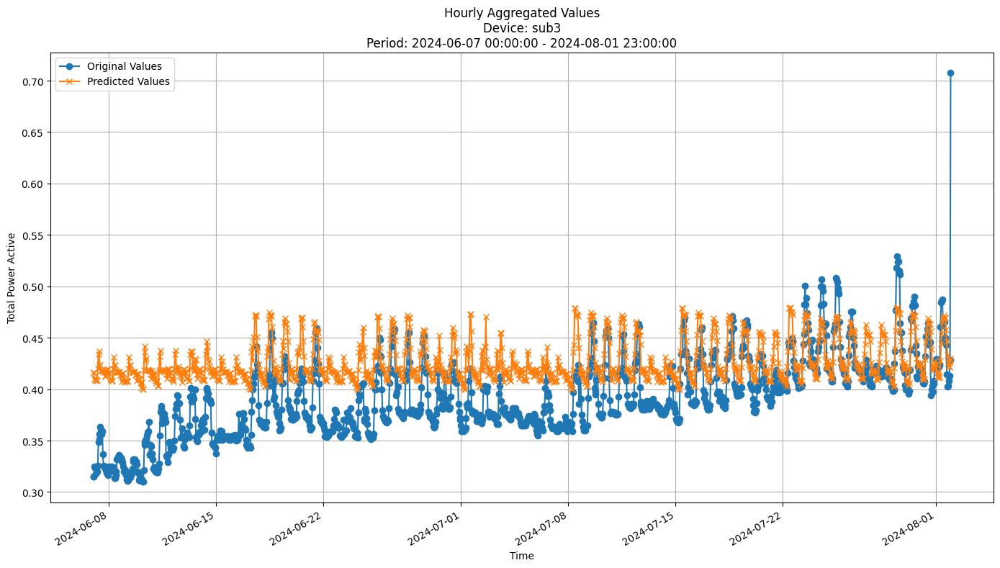


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0449
MAE: 0.0376
MAPE: 10.1322%

Directional Metrics:
Directional Accuracy: 53.3879%
First-Diff Correlation: 0.2910

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


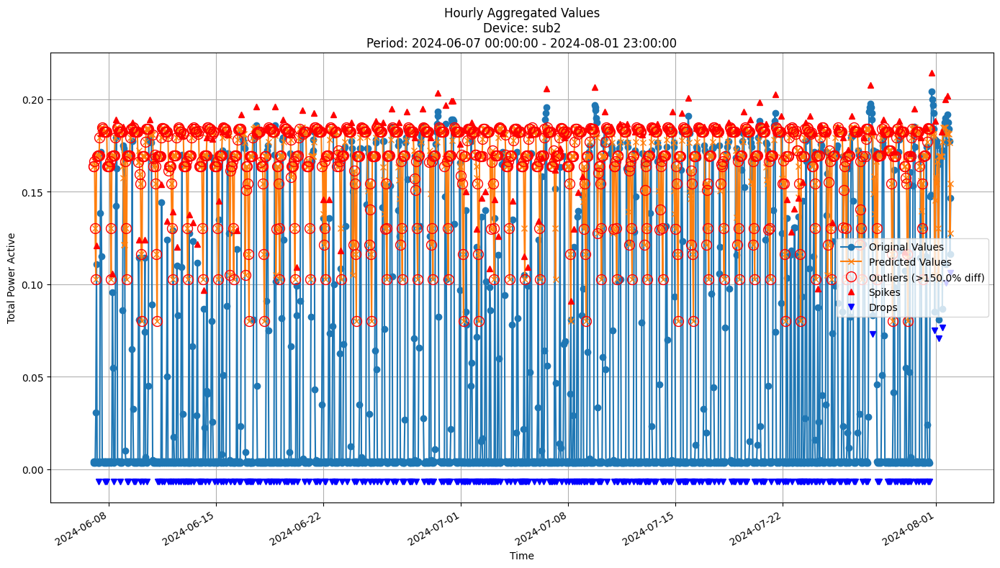


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1378
MAE: 0.1208
MAPE: 2801.3990%

Directional Metrics:
Directional Accuracy: 34.1028%
First-Diff Correlation: 0.0849

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1636
  Recall: 0.0657
  F1 Score: 0.0938
Drops:
  Precision: 0.3455
  Recall: 0.0712
  F1 Score: 0.1180

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.6000
  Recall: 0.2409
  F1 Score: 0.3438
Drops:
  Precision: 0.6727
  Recall: 0.1386
  F1 Score: 0.2298


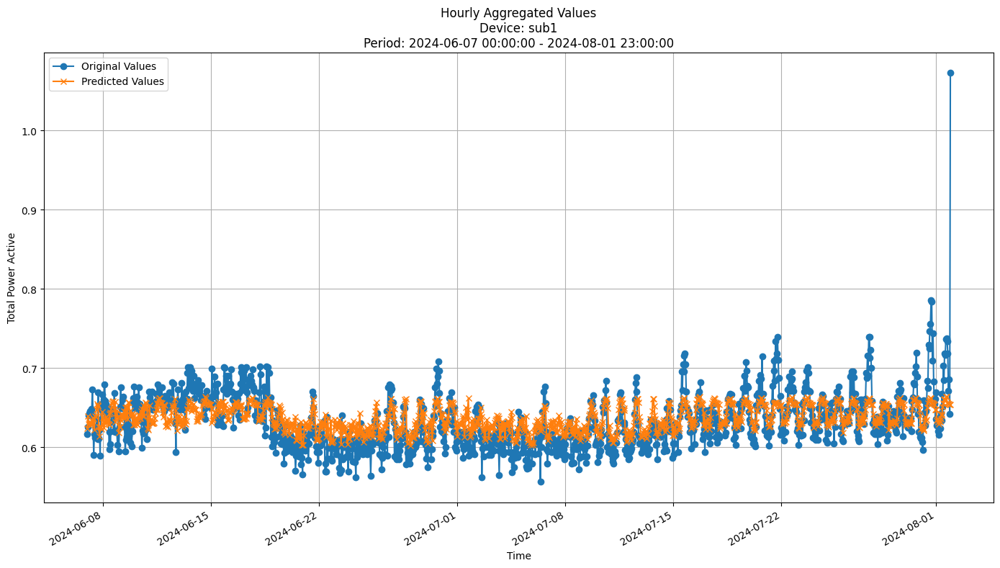


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0282
MAE: 0.0207
MAPE: 3.2532%

Directional Metrics:
Directional Accuracy: 48.4736%
First-Diff Correlation: -0.0224

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [34]:
for device_id in arf_hf_all_train_preds.keys():
    y_train = arf_hf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_hf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

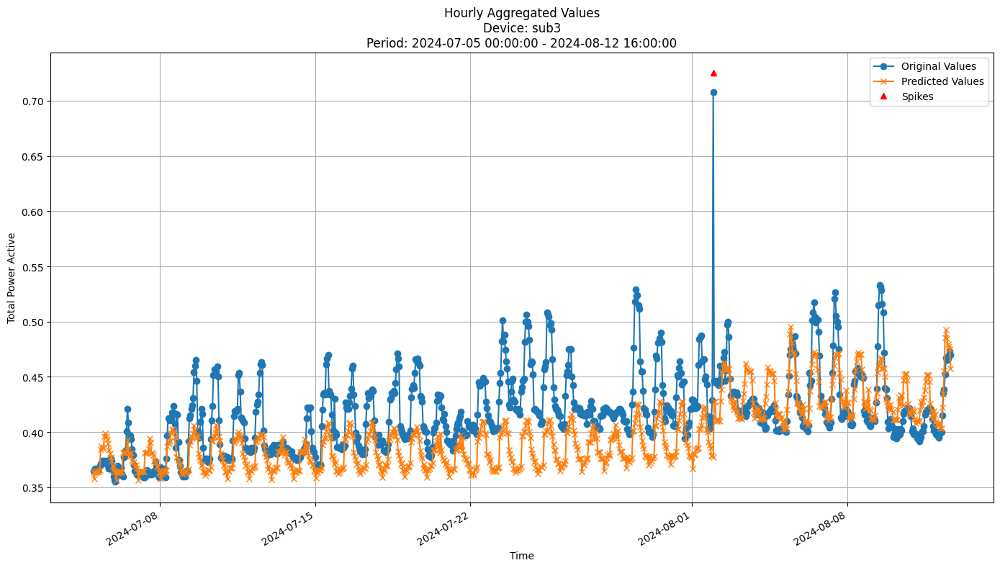


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0360
MAE: 0.0274
MAPE: 6.3199%

Directional Metrics:
Directional Accuracy: 59.8060%
First-Diff Correlation: 0.1260

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


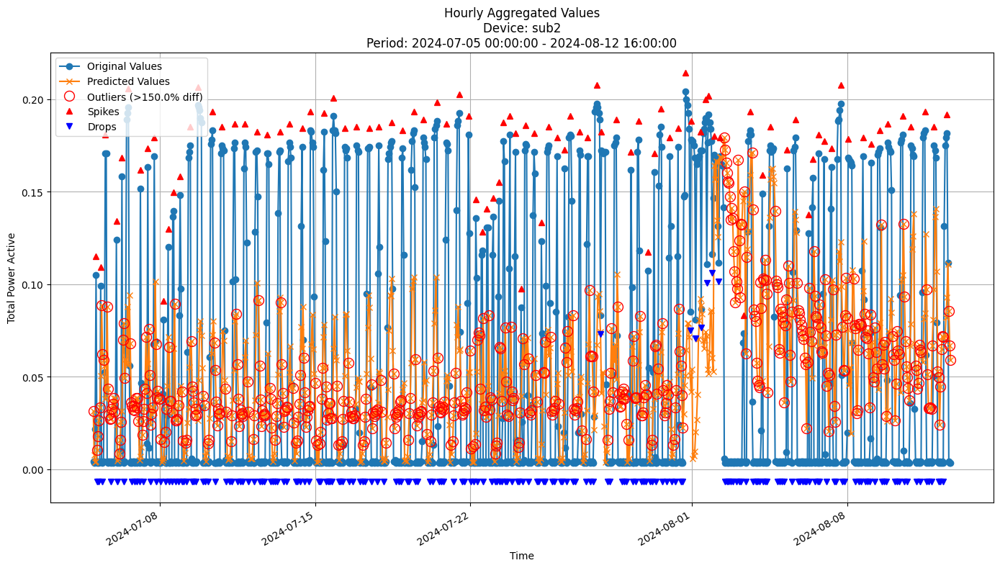


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0712
MAE: 0.0577
MAPE: 686.7001%

Directional Metrics:
Directional Accuracy: 51.5086%
First-Diff Correlation: 0.0023

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


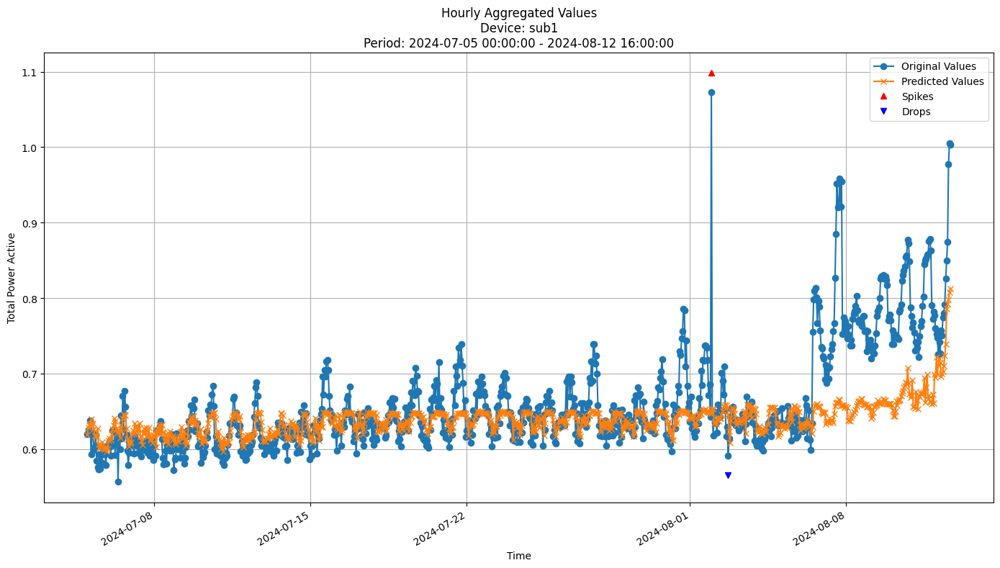


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0590
MAE: 0.0357
MAPE: 4.9057%

Directional Metrics:
Directional Accuracy: 49.0302%
First-Diff Correlation: 0.0012

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [35]:
join_periods = [-1, -2]
# Device iteration
for device_id in arf_hf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_hf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_hf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### FastODT

In [36]:
update_freq = "15min"  # for incremental models put the same as the data frequency to recreate real world scenario

fodt = fastodt.FastODT

fodt_params = {'depth': 50, 
               'grace_period': 48, 
               'grace_period_depth': -1, 
               'split_confidence': 0.05, 
               'max_feature': 0.7, 
               'tie_threshold': 0.05, 
               'bin_type': 'adaptive', 
               'max_bins': 32, 
               'split_criterion': 'vr_rel'}

# Results from hyperparam. tuning
# BEST RMSE: 0.284
#    Best Parameters: {'depth': 100, 'grace_period': 24, 'grace_period_depth': -1, 'split_confidence': 0.5, 'max_feature': 0.7, 'tie_threshold': 0.05, 'bin_type': 'mean', 'split_criterion': 'vr_rel'}
# BEST MAE: 0.166
#    Best Parameters: {'depth': 50, 'grace_period': 24, 'grace_period_depth': 0, 'split_confidence': 0.005, 'max_feature': 0.3, 'tie_threshold': 0.05, 'bin_type': 'mean', 'split_criterion': 'vr_rel'}
# BEST MAPE: 30.526%
#    Best Parameters: {'depth': 50, 'grace_period': 24, 'grace_period_depth': 0, 'split_confidence': 0.005, 'max_feature': 0.3, 'tie_threshold': 0.05, 'bin_type': 'mean', 'split_criterion': 'vr_rel'}
# BEST DIR_ACCURACY: 56.835%
#    Best Parameters: {'depth': 50, 'grace_period': 24, 'grace_period_depth': 0, 'split_confidence': 0.5, 'max_feature': 1.0, 'tie_threshold': 0.05, 'bin_type': 'mean', 'split_criterion': 'vr_rel'}
# BEST FIRST_DIFF_CORR: 39.216%
#    Best Parameters: {'depth': 5, 'grace_period': 96, 'grace_period_depth': 1, 'split_confidence': 0.005, 'max_feature': 1.0, 'tie_threshold': 0.05, 'bin_type': 'mean', 'split_criterion': 'vr_rel'}
# BEST SPIKES_F1: 28.855%
#    Best Parameters: {'depth': 5, 'grace_period': 10, 'grace_period_depth': 1, 'split_confidence': 0.5, 'max_feature': 0.5, 'tie_threshold': 0.05, 'bin_type': 'mean', 'split_criterion': 'vr_rel'}
# BEST DROPS_F1: 16.382%
#    Best Parameters: {'depth': 50, 'grace_period': 48, 'grace_period_depth': 0, 'split_confidence': 0.01, 'max_feature': 0.3, 'tie_threshold': 0.05, 'bin_type': 'mean', 'split_criterion': 'vr_rel'}

In [37]:
fodt_all_train_preds, fodt_all_valid_preds, \
fodt_all_train_metrics, fodt_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=fodt, 
    model_params=fodt_params, 
    train=train, 
    valid=valid, 
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-07-04 23:45:00+02:00
Model's memory usage: 0.445656 MB
Metrics for Device: sub3 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:45:00+02:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0301
	MAE: 0.0154
	MAPE: 3.5484%

Directional Metrics:
	Directional Accuracy: 22.8135%
	First-Diff Correlation: -0.0027

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.1818
		Recall: 0.0625
		F1: 0.0930
	Drops:
		Precision: 0.0625
		Recall: 0.0312
		F1: 0.0417
--------------------------------------------------
Hourly Metrics:
----------------------------------------

Processing devices in split 1:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-08-01 23:45:00+02:00
Model's memory usage: 0.341820 MB
Metrics for Device: sub3 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 16:00:00+02:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0234
	MAE: 0.0168
	MAPE: 3.7692%

Directional Metrics:
	Directional Accuracy: 18.9453%
	First-Diff Correlation: 0.0970

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0278
		Recall: 0.0667
		F1: 0.0392
	Drops:
		Precision: 0.0270
		Recall: 0.0556
		F1: 0.0364
--------------------------------------------------
Hourly Metrics:
-----------------------------------------

#### Results

In [38]:
print("\n\nTrain period metrics:")
fodt_all_time_train_metrics = all_time_aggregation_metrics(fodt_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
fodt_all_time_valid_metrics = all_time_aggregation_metrics(fodt_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: sub3
--------------------------------------------------
15min Metrics:
	RMSE: 0.0213 ± 0.0042
	MAE: 0.0145 ± 0.0012
	MAPE: 3.7858% ± 0.2108%

	Directional Metrics:
		Directional Accuracy: 18.1318% ± 1.2729%
		First-Diff Correlation: 0.0426 ± 0.0469

	Immediate Detection (delta=0):
		Spike Precision: 0.0482 ± 0.0115
		Spike Recall: 0.0810 ± 0.0165
		Spike F1: 0.0577 ± 0.0043
		Drop Precision: 0.0335 ± 0.0081
		Drop Recall: 0.0662 ± 0.0107
		Drop F1: 0.0444 ± 0.0096

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.1159 ± 0.0333
		Spike Recall: 0.1904 ± 0.0291
		Spike F1: 0.1375 ± 0.0175
		Drop Precision: 0.0982 ± 0.0018
		Drop Recall: 0.1979 ± 0.0132
		Drop F1: 0.1311 ± 0.0013
Hourly Metrics:
	RMSE: 0.0177 ± 0.0022
	MAE: 0.0133 ± 0.0012
	MAPE: 3.4780% ± 0.2028%

	Directional Metrics:
		Directional Accuracy: 31.3967% ± 0.1979%
		First-Diff Correlation: 0.1497 ± 0.0162

	Immediate Detection (delta=0):
		Spike 

#### Training plots


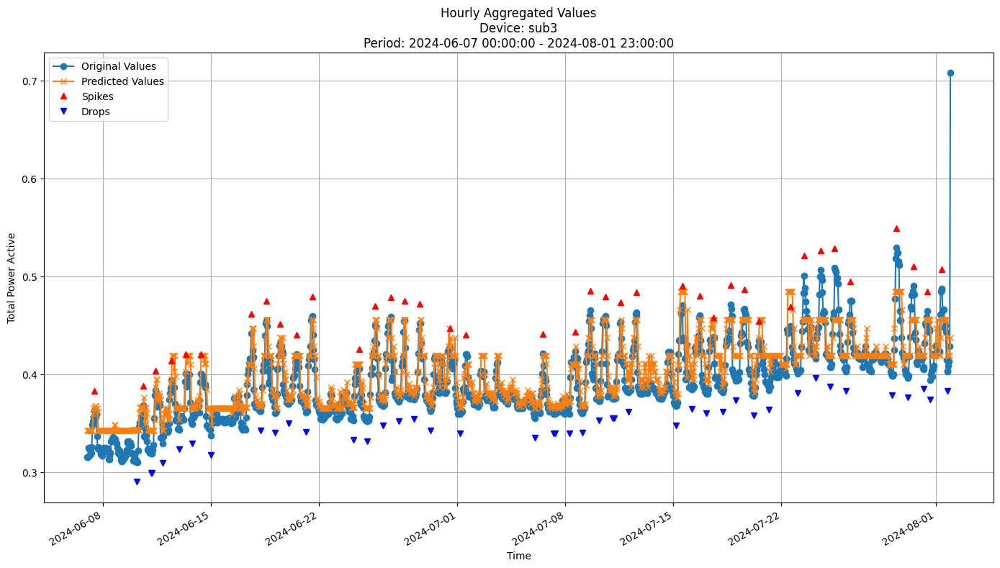


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0198
MAE: 0.0144
MAPE: 3.6808%

Directional Metrics:
Directional Accuracy: 31.1988%
First-Diff Correlation: 0.1659

Immediate Detection (delta=0):
Spikes:
  Precision: 0.2222
  Recall: 0.2051
  F1 Score: 0.2133
Drops:
  Precision: 0.0909
  Recall: 0.0930
  F1 Score: 0.0920

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5833
  Recall: 0.5385
  F1 Score: 0.5600
Drops:
  Precision: 0.4773
  Recall: 0.4884
  F1 Score: 0.4828


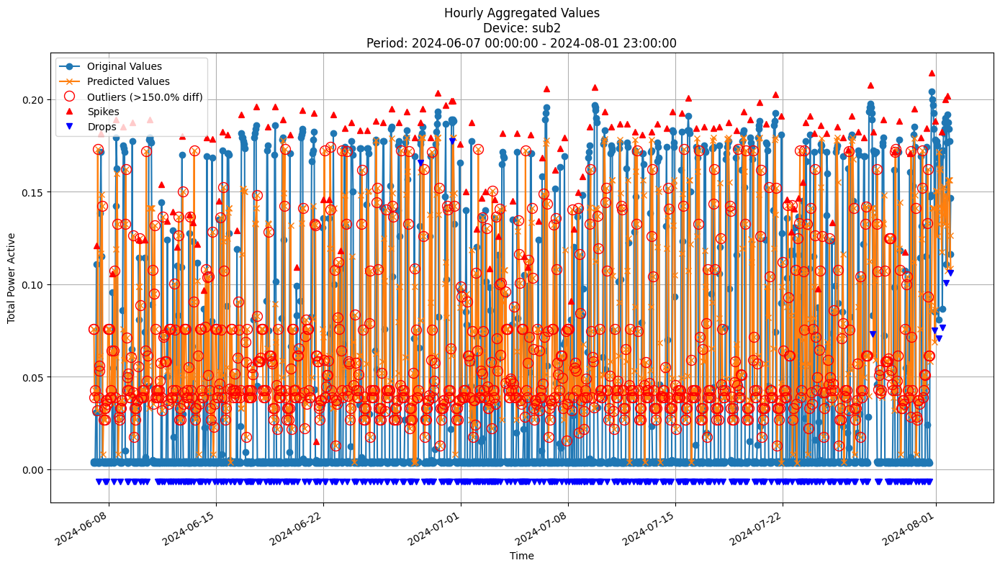


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0685
MAE: 0.0560
MAPE: 968.2443%

Directional Metrics:
Directional Accuracy: 47.2822%
First-Diff Correlation: 0.0586

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1392
  Recall: 0.1583
  F1 Score: 0.1481
Drops:
  Precision: 0.2263
  Recall: 0.1599
  F1 Score: 0.1874

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.3861
  Recall: 0.4388
  F1 Score: 0.4108
Drops:
  Precision: 0.6421
  Recall: 0.4535
  F1 Score: 0.5316


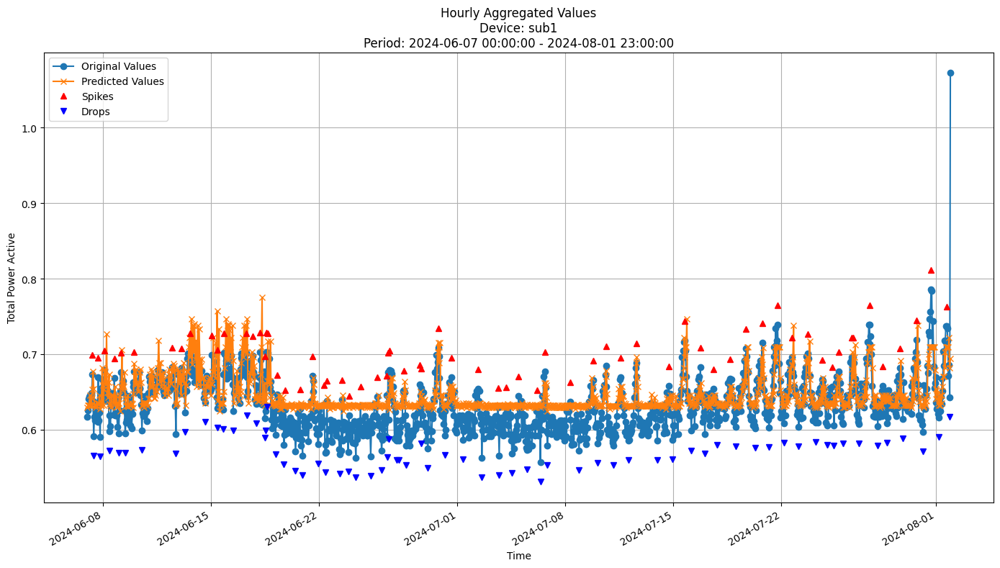


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0296
MAE: 0.0225
MAPE: 3.5852%

Directional Metrics:
Directional Accuracy: 48.6969%
First-Diff Correlation: 0.0559

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0719
  Recall: 0.1765
  F1 Score: 0.1021
Drops:
  Precision: 0.0506
  Recall: 0.1324
  F1 Score: 0.0732

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2096
  Recall: 0.5147
  F1 Score: 0.2979
Drops:
  Precision: 0.1404
  Recall: 0.3676
  F1 Score: 0.2033


In [39]:
for device_id in fodt_all_train_preds.keys():
    y_train = fodt_all_train_preds[device_id][-1]['y_true']
    y_pred_train = fodt_all_train_preds[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id,
                            spike_prominence=SPIKE_PROMINENCE, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

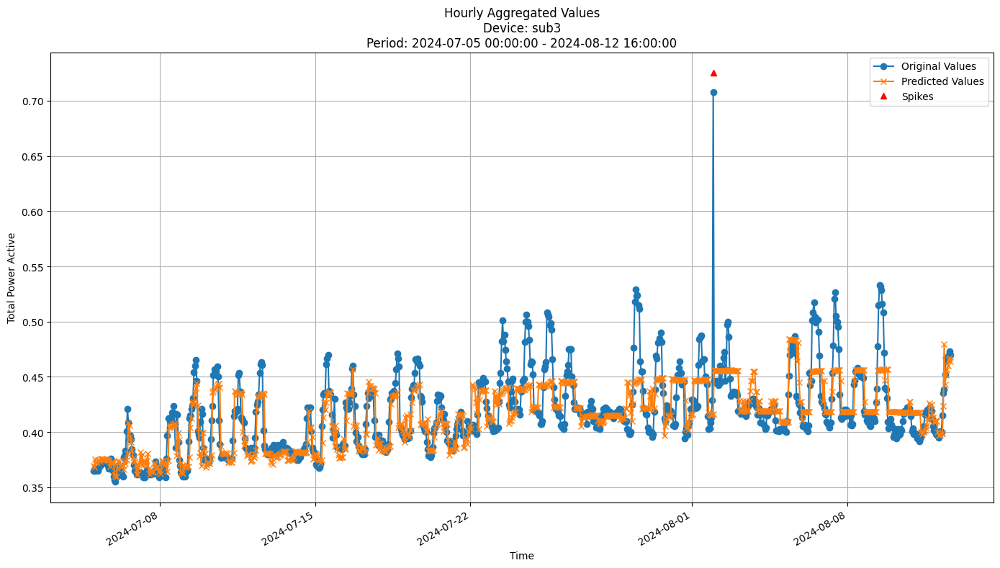


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0224
MAE: 0.0143
MAPE: 3.2706%

Directional Metrics:
Directional Accuracy: 54.0948%
First-Diff Correlation: 0.0329

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


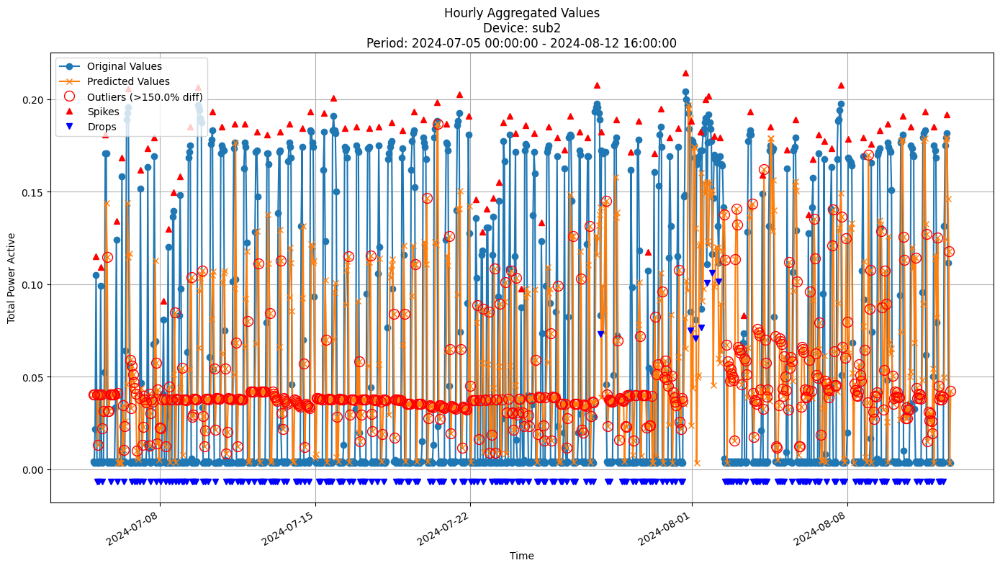


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0632
MAE: 0.0510
MAPE: 616.1387%

Directional Metrics:
Directional Accuracy: 47.0905%
First-Diff Correlation: 0.0264

Immediate Detection (delta=0):
Spikes:
  Precision: 0.3103
  Recall: 0.0938
  F1 Score: 0.1440
Drops:
  Precision: 0.4667
  Recall: 0.0711
  F1 Score: 0.1233

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7241
  Recall: 0.2188
  F1 Score: 0.3360
Drops:
  Precision: 0.7000
  Recall: 0.1066
  F1 Score: 0.1850


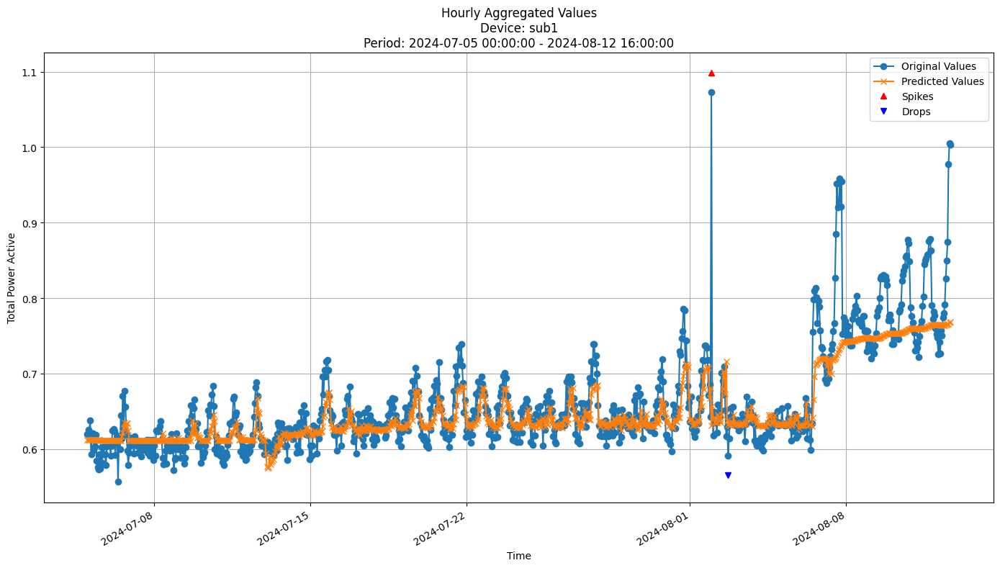


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0387
MAE: 0.0227
MAPE: 3.2046%

Directional Metrics:
Directional Accuracy: 44.3966%
First-Diff Correlation: -0.1384

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [40]:
join_periods = [-1, -2]
# Device iteration
for device_id in fodt_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, fodt_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, fodt_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (FastODT)

In [41]:
update_freq = "15min"  # for incremental models put the same as the data frequency to recreate real world scenario

arf = ARFRegressorFODT
arf_params = dict(n_models=20, 
                  aggregation_method="mean", 
                  grace_period=0,  # by default works for all leaves
                  disable_weighted_vote=True,
                  max_depth=50, 
                  delta=0.05, 
                  tau=0.01, 
                  seed=42, 
                  max_features=0.7, 
                  bin_type='mean', 
                  max_bins=1,
                  split_criterion='vr_rel',)


In [42]:

arf_all_train_preds, arf_all_valid_preds, \
arf_all_train_metrics, arf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=arf,
    model_params=arf_params,
    train=train,
    valid=valid,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-07-04 23:45:00+02:00
Model's memory usage: 176.566147 MB
Metrics for Device: sub3 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:45:00+02:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0294
	MAE: 0.0146
	MAPE: 3.4001%

Directional Metrics:
	Directional Accuracy: 31.5594%
	First-Diff Correlation: -0.0066

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0156
		Recall: 0.0312
		F1: 0.0208
	Drops:
		Precision: 0.0294
		Recall: 0.0625
		F1: 0.0400

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0938
		Recall: 0.1875
		F1: 0.1250
	Drops:
		Precision: 0.0588
		Recall: 0.1250
		F1: 0.0800
--------------------------------------------------
Hourly Metrics:
--------------------------------------

Processing devices in split 1:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-08-01 23:45:00+02:00
Model's memory usage: 133.960289 MB
Metrics for Device: sub3 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 16:00:00+02:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0254
	MAE: 0.0130
	MAPE: 2.9635%

Directional Metrics:
	Directional Accuracy: 51.2695%
	First-Diff Correlation: 0.0887

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0645
		Recall: 0.1333
		F1: 0.0870
	Drops:
		Precision: 0.0690
		Recall: 0.1111
		F1: 0.0851

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0968
		Recall: 0.2000
		F1: 0.1304
	Drops:
		Precision: 0.1034
		Recall: 0.1667
		F1: 0.1277
--------------------------------------------------
Hourly Metrics:
---------------------------------------

#### Results

In [43]:
print("\n\nTrain period metrics:")
arf_all_time_train_metrics = all_time_aggregation_metrics(arf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_all_time_valid_metrics = all_time_aggregation_metrics(arf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: sub3
--------------------------------------------------
15min Metrics:
	RMSE: 0.0219 ± 0.0080
	MAE: 0.0099 ± 0.0012
	MAPE: 2.5684% ± 0.2528%

	Directional Metrics:
		Directional Accuracy: 43.8552% ± 0.0227%
		First-Diff Correlation: 0.2970 ± 0.1642

	Immediate Detection (delta=0):
		Spike Precision: 0.0459 ± 0.0067
		Spike Recall: 0.0932 ± 0.0287
		Spike F1: 0.0612 ± 0.0124
		Drop Precision: 0.1053 ± 0.0030
		Drop Recall: 0.1722 ± 0.0278
		Drop F1: 0.1302 ± 0.0104

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.1118 ± 0.0040
		Spike Recall: 0.2229 ± 0.0454
		Spike F1: 0.1480 ± 0.0138
		Drop Precision: 0.1665 ± 0.0169
		Drop Recall: 0.2748 ± 0.0637
		Drop F1: 0.2065 ± 0.0314
Hourly Metrics:
	RMSE: 0.0144 ± 0.0035
	MAE: 0.0083 ± 0.0011
	MAPE: 2.1447% ± 0.2195%

	Directional Metrics:
		Directional Accuracy: 58.5847% ± 0.0154%
		First-Diff Correlation: 0.3653 ± 0.0182

	Immediate Detection (delta=0):
		Spike 

#### Training plots

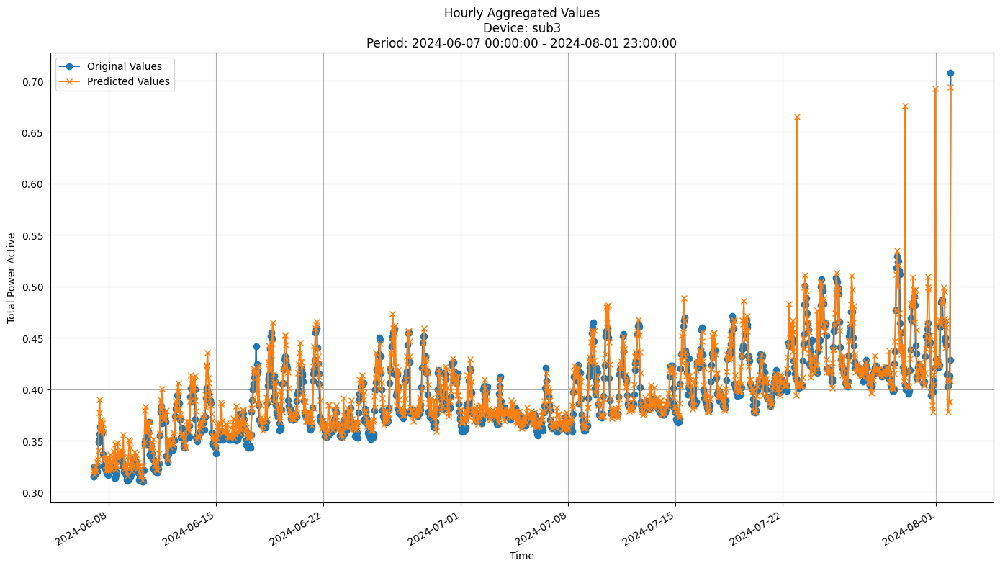


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0179
MAE: 0.0093
MAPE: 2.3642%

Directional Metrics:
Directional Accuracy: 58.6001%
First-Diff Correlation: 0.3471

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


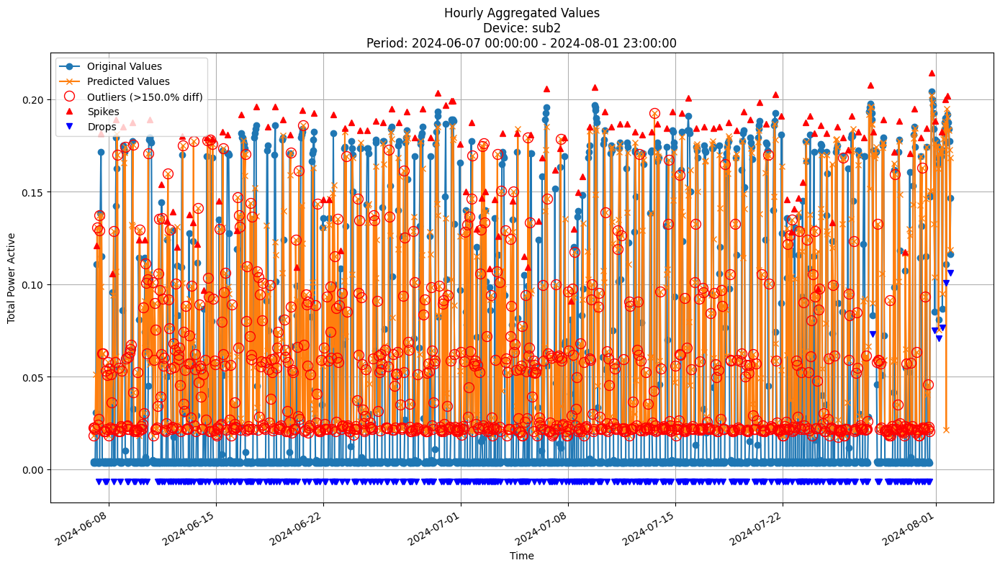


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0596
MAE: 0.0445
MAPE: 769.6361%

Directional Metrics:
Directional Accuracy: 57.7811%
First-Diff Correlation: 0.2443

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


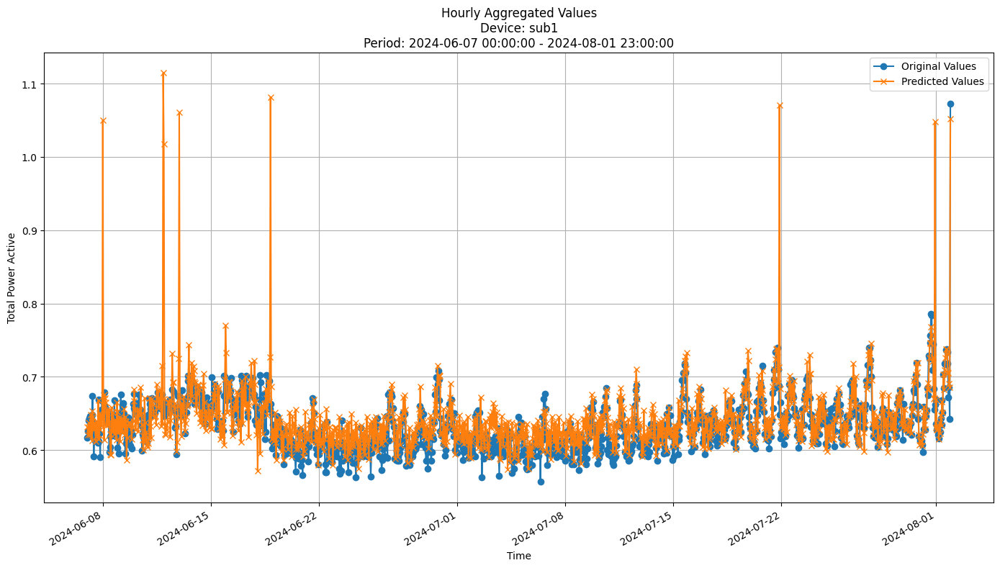


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0385
MAE: 0.0205
MAPE: 3.2587%

Directional Metrics:
Directional Accuracy: 54.5048%
First-Diff Correlation: 0.1895

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [44]:
for device_id in arf_all_train_preds.keys():
    y_train = arf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

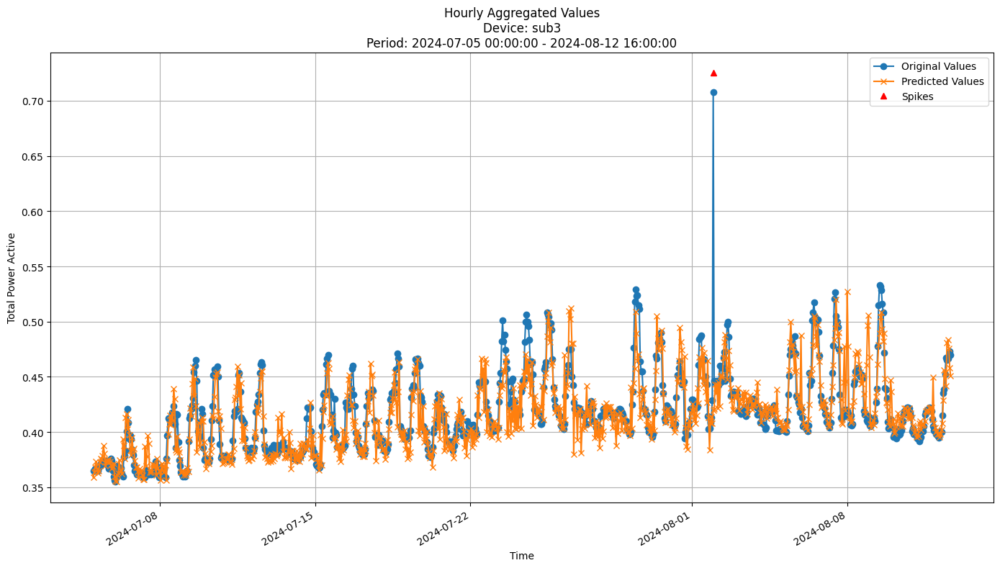


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0203
MAE: 0.0124
MAPE: 2.8633%

Directional Metrics:
Directional Accuracy: 52.9095%
First-Diff Correlation: 0.1268

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


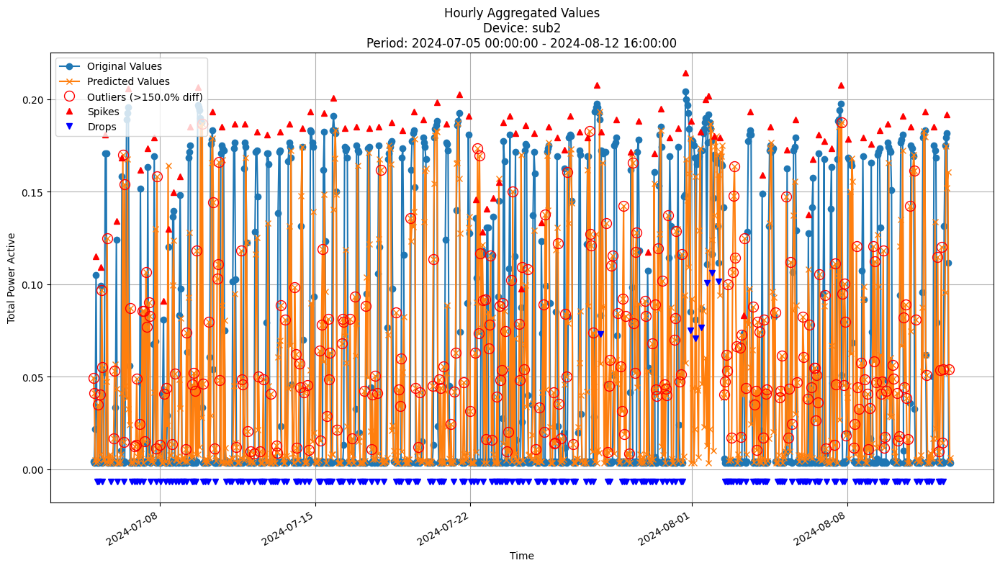


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0694
MAE: 0.0467
MAPE: 496.2337%

Directional Metrics:
Directional Accuracy: 50.8621%
First-Diff Correlation: 0.0872

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


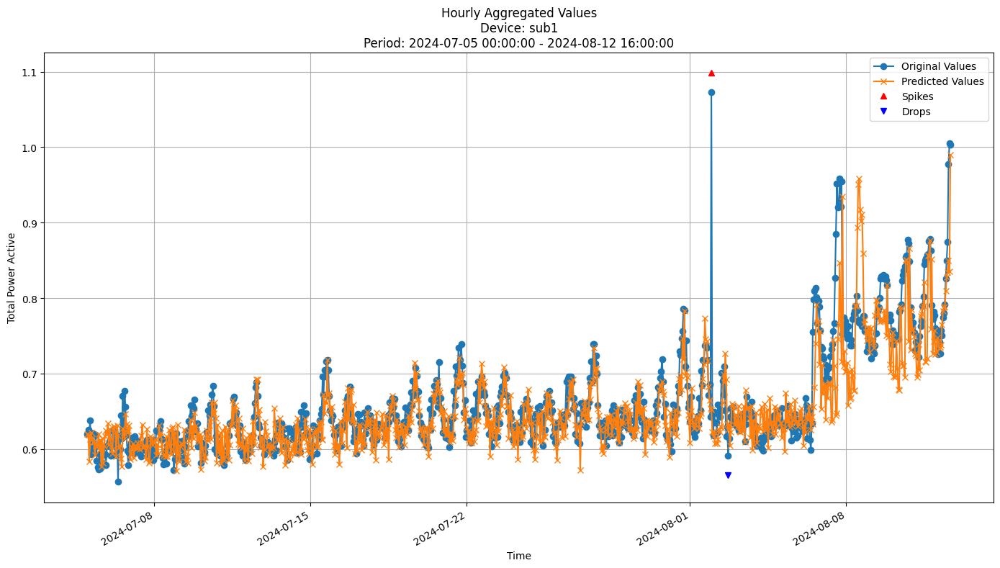


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0408
MAE: 0.0248
MAPE: 3.5714%

Directional Metrics:
Directional Accuracy: 49.5690%
First-Diff Correlation: 0.0069

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [45]:
join_periods = [-1, -2]
# Device iteration
for device_id in arf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### iNcubation Boost

In [46]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario


incb = IncubationBoost
incb_params = {'base_learner': fastodt.FastODT, 
                 'length': 10, 
                 'learning_rate': 0.5, 
                 'depth': 5, 
                 'grace_period': 0, 
                 'grace_period_depth': -1, 
                 'split_confidence': 0.5, 
                 'max_feature': 1.0, 
                 'tie_threshold': 0.05, 
                 'bin_type': 'adaptive', 
                 'max_bins': 8, 
                 'split_criterion': 'vr_rel', 
                 'verbose': False}

In [47]:
incb_all_train_preds, incb_all_valid_preds, \
incb_all_train_metrics, incb_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=incb, 
    model_params=incb_params, 
    train=train, 
    valid=valid, 
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    # end_split=1,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-07-04 23:45:00+02:00
Model's memory usage: 0.470520 MB
Metrics for Device: sub3 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:45:00+02:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0951
	MAE: 0.0864
	MAPE: 20.4565%

Directional Metrics:
	Directional Accuracy: 9.7879%
	First-Diff Correlation: -0.0051

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0357
		Recall: 0.0625
		F1: 0.0455

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0182
		Recall: 0.0312
		F1: 0.0230
	Drops:
		Precision: 0.0536
		Recall: 0.0938
		F1: 0.0682
--------------------------------------------------
Hourly Metrics:
----------------------------------------

Processing devices in split 1:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-08-01 23:45:00+02:00
Model's memory usage: 0.470497 MB
Metrics for Device: sub3 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 16:00:00+02:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1105
	MAE: 0.1056
	MAPE: 24.1669%

Directional Metrics:
	Directional Accuracy: 8.7891%
	First-Diff Correlation: 0.0404

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Hourly Metrics:
-----------------------------------------

#### Results

In [48]:
print("\n\nTrain period metrics:")
incb_all_time_train_metrics = all_time_aggregation_metrics(incb_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
incb_all_time_valid_metrics = all_time_aggregation_metrics(incb_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)
# Hourly Metrics:
# 	RMSE: 0.4348 ± 0.1387
# 	MAE: 0.3140 ± 0.0869
# 	MAPE: 60.2407% ± 12.6513%
# 	Dir Accuracy: 57.2071% ± 2.1944%
# 	First-Diff Correlation: 0.3343 ± 0.0699



Train period metrics:


Aggregated Metrics Across Periods
Device ID: sub3
--------------------------------------------------
15min Metrics:
	RMSE: 0.0671 ± 0.0110
	MAE: 0.0578 ± 0.0096
	MAPE: 14.4660% ± 1.9969%

	Directional Metrics:
		Directional Accuracy: 12.3826% ± 0.8663%
		First-Diff Correlation: 0.0118 ± 0.0106

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0348 ± 0.0015
		Drop Recall: 0.0376 ± 0.0068
		Drop F1: 0.0360 ± 0.0040

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0192 ± 0.0192
		Spike Recall: 0.0244 ± 0.0244
		Spike F1: 0.0215 ± 0.0215
		Drop Precision: 0.1167 ± 0.0167
		Drop Recall: 0.1226 ± 0.0004
		Drop F1: 0.1190 ± 0.0090
Hourly Metrics:
	RMSE: 0.0664 ± 0.0105
	MAE: 0.0576 ± 0.0096
	MAPE: 14.4343% ± 2.0203%

	Directional Metrics:
		Directional Accuracy: 18.3245% ± 1.3476%
		First-Diff Correlation: 0.0968 ± 0.0044

	Immediate Detection (delta=0):
		Spik

#### Train plots

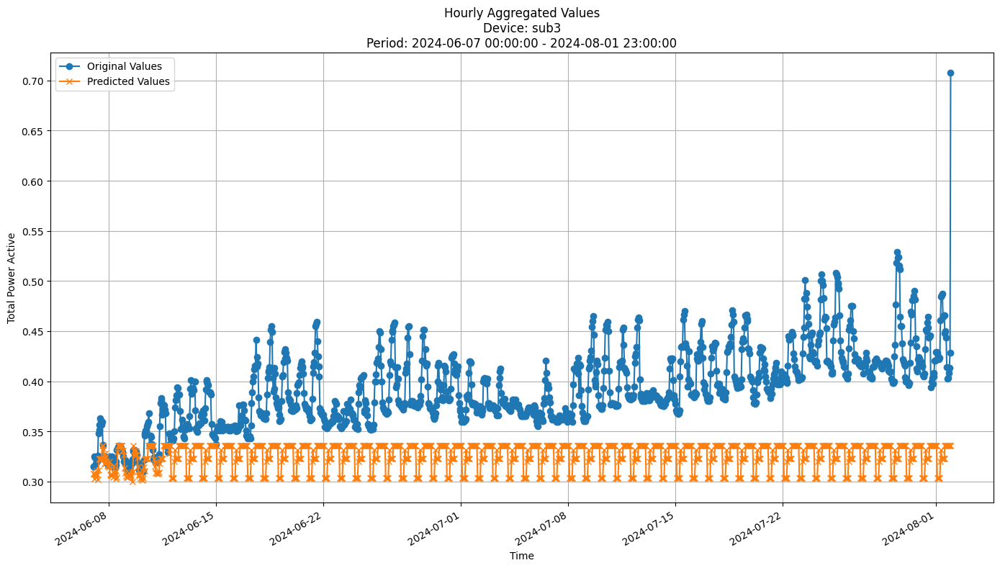


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0769
MAE: 0.0672
MAPE: 16.4546%

Directional Metrics:
Directional Accuracy: 16.9769%
First-Diff Correlation: 0.0924

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


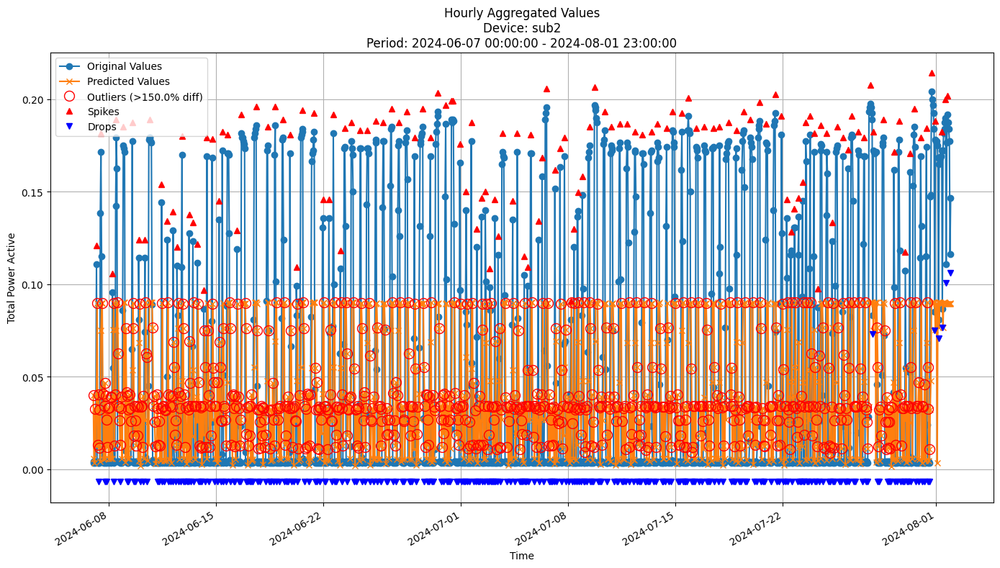


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0622
MAE: 0.0474
MAPE: 509.3532%

Directional Metrics:
Directional Accuracy: 43.1869%
First-Diff Correlation: -0.0727

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


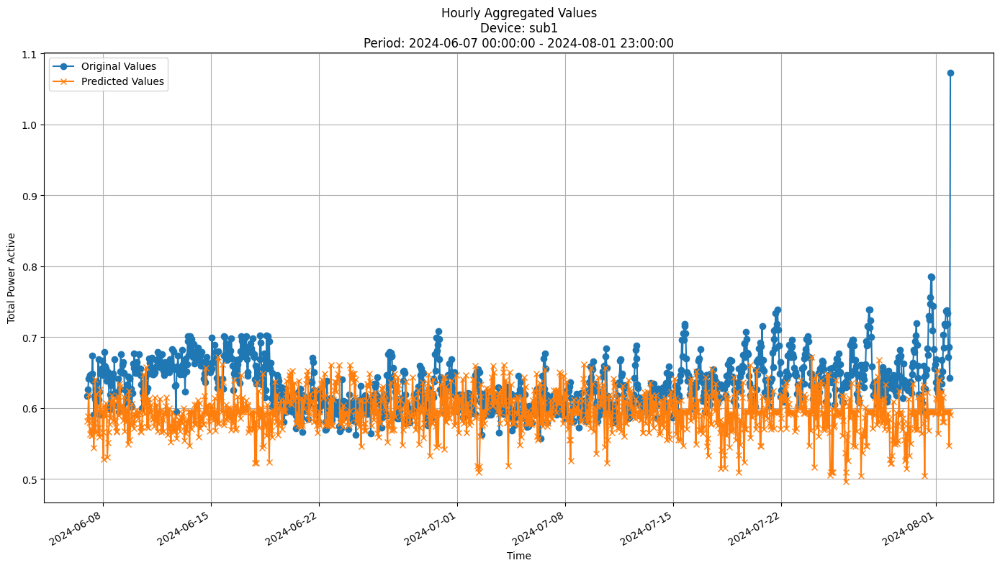


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0618
MAE: 0.0486
MAPE: 7.4508%

Directional Metrics:
Directional Accuracy: 44.8995%
First-Diff Correlation: -0.0484

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [49]:
for device_id in incb_all_train_preds.keys():
    y_train = incb_all_train_preds[device_id][-1]['y_true']
    y_pred_train = incb_all_train_preds[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

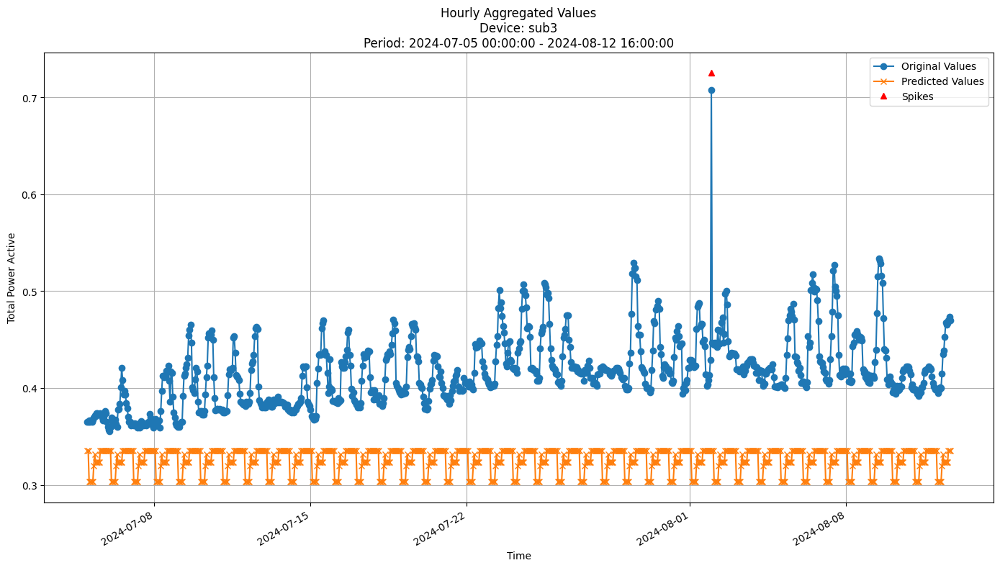


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0983
MAE: 0.0917
MAPE: 21.5191%

Directional Metrics:
Directional Accuracy: 14.4397%
First-Diff Correlation: 0.0856

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


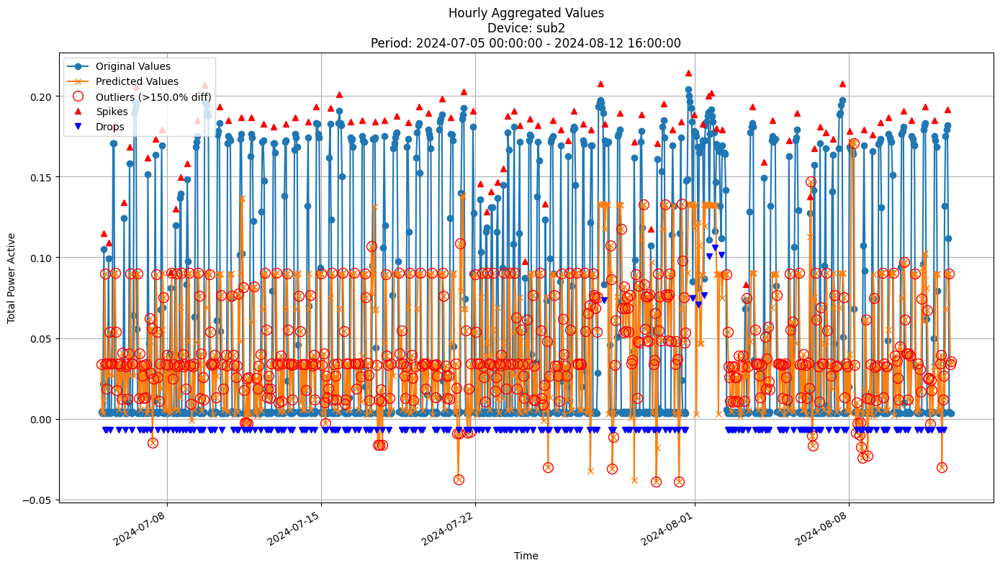


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0647
MAE: 0.0503
MAPE: 532.5114%

Directional Metrics:
Directional Accuracy: 42.5647%
First-Diff Correlation: -0.0277

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


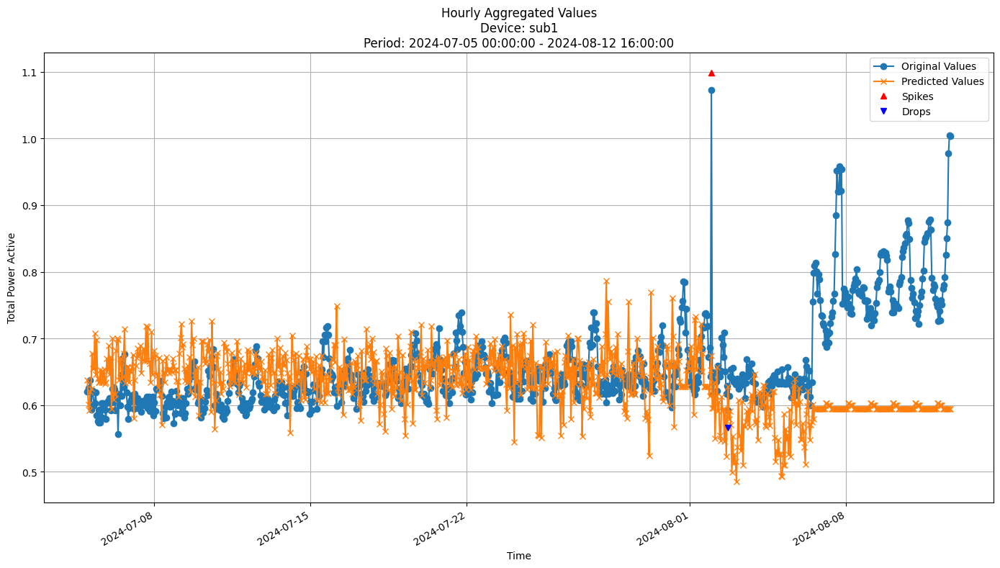


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0973
MAE: 0.0702
MAPE: 10.0349%

Directional Metrics:
Directional Accuracy: 38.7931%
First-Diff Correlation: 0.0006

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [50]:
join_periods = [-1, -2]
# Device iteration
for device_id in incb_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, incb_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, incb_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

# Test-set Model Evaluation
(`train[-1]` + `valid[-1]`) vs `test`

In [51]:
# Initialize the models and params for test-set evaluation
models_classes = [bl_prev, bl_mean, gbdt, rf, hoef, arf_hf, fodt, arf, incb]
models_params = [bl_prev_params, bl_mean_params, gbdt_params, rf_params,
                 hoef_params, arf_hf_params, fodt_params, arf_params, incb_params]

model_test_results = {}
for model, params in zip(models_classes, models_params):
    if model in [gbdt, rf, bl_mean]:
        # Batch learning models
        incremental = False
        update_freq = "14D"
        print(f"\n\n\nModel: {model.__name__} - update_freq: {update_freq}")
    else:
        # Incremental learning models
        incremental = True
        update_freq = "15m"
        print(f"\n\n\nModel: {model.__name__} - update_freq: {update_freq}")

    _, test_preds, \
    _, test_metrics = test_set_seq_fit_predict(
        model_class=model,
        model_params=params,
        train=train, 
        valid=valid,
        test=test,
        incremental=incremental, 
        data_freq=DATA_FREQUENCY,
        forecast_horizon=FORECAST_HORIZON,
        features=FEATURES,
        update_freq=update_freq,
        spike_prominence=SPIKE_PROMINENCE,
        normalize_robust=True,
        predict_train=False,
        verbose=1
    )
    model_test_results[model.__name__] = {
        "test_preds": test_preds,
        "test_metrics": test_metrics
    }




Model: PreviousValueRegressor - update_freq: 15m


Processing devices for test predictions:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-08-12 16:00:00+02:00
Model's memory usage: 0.000374 MB
Metrics for Device: sub2 | Period: 2024-08-12 16:30:00+02:00 - 2024-08-29 14:15:00+02:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0551
	MAE: 0.0221
	MAPE: 1848768320183.1677%

Directional Metrics:
	Directional Accuracy: 47.8127%
	First-Diff Correlation: 0.0443

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Hourly Metrics:
-----------------------------

Processing devices for test predictions:   0%|          | 0/3 [00:00<?, ?it/s]


Retraining model on data from 2024-06-07 00:00:00+02:00 to 2024-08-12 16:00:00+02:00

Time: 0.00 seconds
Predicting for chunk from 2024-08-12 16:30:00+02:00 to 2024-08-26 16:30:00+02:00

-------------------------

Retraining model on data from 2024-06-07 00:00:00+02:00 to 2024-08-26 16:30:00+02:00

Time: 0.00 seconds
Predicting for chunk from 2024-08-26 16:45:00+02:00 to 2024-08-29 14:15:00+02:00

-------------------------
Model's memory usage: 0.024391 MB
Metrics for Device: sub2 | Period: 2024-08-12 16:30:00+02:00 - 2024-08-29 14:15:00+02:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0829
	MAE: 0.0702
	MAPE: 12479186160413.0762%

Directional Metrics:
	Directional Accuracy: 43.8078%
	First-Diff Correlation: -0.0363

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection

Processing devices for test predictions:   0%|          | 0/3 [00:00<?, ?it/s]

... (9 outputs left out)

Processing devices for test predictions:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-08-12 16:00:00+02:00
Model's memory usage: 520.081871 MB
Metrics for Device: sub2 | Period: 2024-08-12 16:30:00+02:00 - 2024-08-29 14:15:00+02:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0752
	MAE: 0.0423
	MAPE: 924384160527.8513%

Directional Metrics:
	Directional Accuracy: 31.3001%
	First-Diff Correlation: 0.0932

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Hourly Metrics:
----------------------------

Processing devices for test predictions:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-08-12 16:00:00+02:00
Model's memory usage: 0.389389 MB
Metrics for Device: sub2 | Period: 2024-08-12 16:30:00+02:00 - 2024-08-29 14:15:00+02:00
15min Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0784
	MAE: 0.0602
	MAPE: 8935713547038.7676%

Directional Metrics:
	Directional Accuracy: 32.7788%
	First-Diff Correlation: -0.0280

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Hourly Metrics:
----------------------------

In [52]:
for model in models_classes:
    model_test_results[model.__name__]['test_metrics'] = all_time_aggregation_metrics(
        model_test_results[model.__name__]['test_metrics'],
        data_freq=DATA_FREQUENCY,
        verbose=False)

In [53]:
model_test_results['ARFRegressorFODT']['test_preds']['sub2']

[{'period': '2024-08-12 16:30:00+02:00 - 2024-08-29 14:15:00+02:00',
  'y_true': 2024-08-12 16:30:00+02:00    0.003333
  2024-08-12 16:45:00+02:00    0.006667
  2024-08-12 17:00:00+02:00    0.003333
  2024-08-12 17:15:00+02:00    0.003333
  2024-08-12 17:30:00+02:00    0.003333
                                 ...   
  2024-08-29 13:15:00+02:00    0.003333
  2024-08-29 13:30:00+02:00    0.003333
  2024-08-29 13:45:00+02:00    0.003333
  2024-08-29 14:00:00+02:00    0.003333
  2024-08-29 14:15:00+02:00    0.003333
  Length: 1624, dtype: float64,
  'y_pred': 2024-08-12 16:30:00+02:00    0.003333
  2024-08-12 16:45:00+02:00    0.003333
  2024-08-12 17:00:00+02:00    0.006333
  2024-08-12 17:15:00+02:00    0.154000
  2024-08-12 17:30:00+02:00    0.138333
                                 ...   
  2024-08-29 13:15:00+02:00    0.006667
  2024-08-29 13:30:00+02:00    0.006667
  2024-08-29 13:45:00+02:00    0.006667
  2024-08-29 14:00:00+02:00    0.012167
  2024-08-29 14:15:00+02:00    0.175833

# Model Comparison

In [54]:
AGG_LEVEL = "hourly"
METRICS = ["rmse", "mae", "mape", "dir_accuracy", "first_diff_corr"]
PERC_METRICS = ["mape", "dir_accuracy", "first_diff_corr"]
# SPIKES_METRICS = ["spikes_immediate.precision", "spikes_immediate.recall", "spikes_immediate.f1",
#                   "spikes_delayed.precision", "spikes_delayed.recall", "spikes_delayed.f1",
#                   "drops_immediate.precision", "drops_immediate.recall", "drops_immediate.f1",
#                   "drops_delayed.precision", "drops_delayed.recall", "drops_delayed.f1"]
SPIKES_METRICS = ["spikes_immediate.f1", "spikes_delayed.f1",
                  "drops_immediate.f1", "drops_delayed.f1"]

METRICS.extend(SPIKES_METRICS)
PERC_METRICS.extend(SPIKES_METRICS)

## Test results

In [55]:
MODEL_TEST_METRICS = {
    "BL_Prev": model_test_results[bl_prev.__name__]["test_metrics"],
    "BL_Mean": model_test_results[bl_mean.__name__]["test_metrics"],
    "GBDT": model_test_results[gbdt.__name__]["test_metrics"],
    "RandomForest": model_test_results[rf.__name__]["test_metrics"],
    "HoeffdingTree": model_test_results[hoef.__name__]["test_metrics"],
    "ARF_Hoeffding": model_test_results[arf_hf.__name__]["test_metrics"],
    "FastODT": model_test_results[fodt.__name__]["test_metrics"],
    "ARF_FastODT": model_test_results[arf.__name__]["test_metrics"],
    "IncubationBoost": model_test_results[incb.__name__]["test_metrics"],
}

In [56]:
def format_metric(val, is_perc=False):
    if isinstance(val, dict) and "mean" in val and "std" in val:
        mean = val["mean"]
        std = val["std"]
        if is_perc:
            mean = mean * 100
            std = std * 100
        return f"{mean:.3f} ± {std:.3f}"
    if is_perc:
        return f"{val*100:.3f}" if val is not None else None
    return f"{val:.3f}" if val is not None else None

def display_aggregated_results(model_metrics, device_ids, agg_level):
    for device_id in device_ids:
        rows = []
        for model, mdict in model_metrics.items():
            if device_id in mdict and agg_level in mdict[device_id]:
                vals = mdict[device_id][agg_level]
                row = [model]
                for m in METRICS:
                    is_perc = (m in PERC_METRICS)
                    row.append(format_metric(vals.get(m, None), is_perc=is_perc))
                rows.append(row)
        df = pd.DataFrame(rows, columns=["Model", "RMSE", "MAE", "MAPE (%)", "Directional Accuracy (%)", "First Diff Corr (%)",
                                         "Spikes Immediate F1 (%)", "Spikes Delayed F1 (%)", "Drops Immediate F1 (%)", "Drops Delayed F1 (%)"])
        print(f"\n\nDevice: {device_id} | Aggregation: {agg_level}")
        display(df)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Example data: model names and MAE values for two sites
model_names = ['BL_Prev', 'BL_Mean', 'GBDT', 'RandomForest', 'HoeffdingTree', 'ARF_Hoeffding', 'FastODT', 'ARF_FastODT', 'IncubationBoost']
mae_values = [
    [0.15, 0.18, 0.13, 0.12, 0.16, 0.14, 0.17, 0.13, 0.19],  # Site 1
    [0.17, 0.20, 0.14, 0.13, 0.18, 0.15, 0.19, 0.15, 0.21],  # Site 2
]
site_labels = ['Site 1', 'Site 2']
site_colors = ['#4F8DFD', '#FDC14F']

num_sites = len(mae_values)
x = np.arange(len(model_names))
width = 0.8 / num_sites  # Make bars fit nicely

fig, ax = plt.subplots(figsize=(12, 6))
bars = []
for i in range(num_sites):
    bars.append(
        ax.bar(
            x - 0.4 + width/2 + i*width,
            mae_values[i],
            width,
            label=site_labels[i],
            color=site_colors[i % len(site_colors)]
        )
    )

ax.set_ylabel('MAE', fontsize=14)
ax.set_xlabel('Model', fontsize=14)
ax.set_title('Model MAE Comparison by Site', fontsize=16, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(model_names, rotation=20, ha='right', fontsize=12)
ax.legend(title='Site', fontsize=12, title_fontsize=13)
ax.grid(axis='y', linestyle='--', alpha=0.6)

# Annotate bars with values
for bar_group in bars:
    for bar in bar_group:
        height = bar.get_height()
        ax.annotate(f'{height:.2f}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

In [57]:
device_ids = set()
for m in MODEL_TEST_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)

print("\n============================15-Min Test Results============================")
display_aggregated_results(MODEL_TEST_METRICS, device_ids, "15min")
print("\n\n============================Hourly Test Results============================")
display_aggregated_results(MODEL_TEST_METRICS, device_ids, "hourly")


============================15-Min Test Results============================


Device: sub1 | Aggregation: 15min


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.033 ± 0.000,0.016 ± 0.000,1.805 ± 0.000,22.859 ± 0.000,-20.452 ± 0.000,9.524 ± 0.000,23.810 ± 0.000,22.727 ± 0.000,22.727 ± 0.000
1,BL_Mean,0.236 ± 0.000,0.225 ± 0.000,25.154 ± 0.000,23.537 ± 0.000,3.716 ± 0.000,0.000 ± 0.000,4.444 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
2,GBDT,0.093 ± 0.000,0.073 ± 0.000,7.888 ± 0.000,26.186 ± 0.000,-1.073 ± 0.000,0.000 ± 0.000,6.452 ± 0.000,4.167 ± 0.000,16.667 ± 0.000
3,RandomForest,0.071 ± 0.000,0.049 ± 0.000,5.339 ± 0.000,40.789 ± 0.000,-0.447 ± 0.000,0.000 ± 0.000,4.444 ± 0.000,4.255 ± 0.000,12.766 ± 0.000
4,HoeffdingTree,0.186 ± 0.000,0.169 ± 0.000,18.792 ± 0.000,24.892 ± 0.000,-1.439 ± 0.000,4.348 ± 0.000,4.348 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
5,ARF_Hoeffding,0.070 ± 0.000,0.051 ± 0.000,5.554 ± 0.000,34.935 ± 0.000,0.563 ± 0.000,0.000 ± 0.000,4.651 ± 0.000,13.636 ± 0.000,36.364 ± 0.000
6,FastODT,0.089 ± 0.000,0.060 ± 0.000,6.491 ± 0.000,24.091 ± 0.000,-3.272 ± 0.000,0.000 ± 0.000,3.333 ± 0.000,6.667 ± 0.000,13.333 ± 0.000
7,ARF_FastODT,0.033 ± 0.000,0.019 ± 0.000,2.194 ± 0.000,40.542 ± 0.000,-8.653 ± 0.000,4.444 ± 0.000,22.222 ± 0.000,0.000 ± 0.000,13.043 ± 0.000
8,IncubationBoost,0.293 ± 0.000,0.283 ± 0.000,31.744 ± 0.000,15.465 ± 0.000,-4.190 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000




Device: sub2 | Aggregation: 15min


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.055 ± 0.000,0.022 ± 0.000,1848768320183.168 ± 0.000,47.813 ± 0.000,4.429 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
1,BL_Mean,0.083 ± 0.000,0.070 ± 0.000,12479186160413.076 ± 0.000,43.808 ± 0.000,-3.629 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
2,GBDT,0.062 ± 0.000,0.051 ± 0.000,8688658400025.891 ± 0.000,44.794 ± 0.000,21.749 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
3,RandomForest,0.062 ± 0.000,0.045 ± 0.000,6752467277252.513 ± 0.000,30.622 ± 0.000,14.425 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
4,HoeffdingTree,0.069 ± 0.000,0.056 ± 0.000,5688761423578.475 ± 0.000,41.836 ± 0.000,23.078 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
5,ARF_Hoeffding,0.066 ± 0.000,0.055 ± 0.000,11943302208482.906 ± 0.000,37.523 ± 0.000,19.725 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
6,FastODT,0.066 ± 0.000,0.050 ± 0.000,6670972355123.551 ± 0.000,41.774 ± 0.000,11.938 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
7,ARF_FastODT,0.075 ± 0.000,0.042 ± 0.000,924384160527.851 ± 0.000,31.300 ± 0.000,9.320 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
8,IncubationBoost,0.078 ± 0.000,0.060 ± 0.000,8935713547038.768 ± 0.000,32.779 ± 0.000,-2.805 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000




Device: sub3 | Aggregation: 15min


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.014 ± 0.000,0.008 ± 0.000,1.971 ± 0.000,11.707 ± 0.000,-33.039 ± 0.000,8.333 ± 0.000,20.833 ± 0.000,3.704 ± 0.000,14.815 ± 0.000
1,BL_Mean,0.017 ± 0.000,0.013 ± 0.000,3.170 ± 0.000,18.977 ± 0.000,4.421 ± 0.000,4.651 ± 0.000,13.953 ± 0.000,0.000 ± 0.000,16.327 ± 0.000
2,GBDT,0.013 ± 0.000,0.009 ± 0.000,2.263 ± 0.000,65.989 ± 0.000,21.334 ± 0.000,3.774 ± 0.000,11.321 ± 0.000,3.704 ± 0.000,7.407 ± 0.000
3,RandomForest,0.013 ± 0.000,0.009 ± 0.000,2.115 ± 0.000,65.619 ± 0.000,21.084 ± 0.000,0.000 ± 0.000,7.692 ± 0.000,0.000 ± 0.000,6.897 ± 0.000
4,HoeffdingTree,0.024 ± 0.000,0.019 ± 0.000,4.674 ± 0.000,16.513 ± 0.000,-18.313 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,5.714 ± 0.000,5.714 ± 0.000
5,ARF_Hoeffding,0.025 ± 0.000,0.021 ± 0.000,5.301 ± 0.000,34.196 ± 0.000,5.392 ± 0.000,4.082 ± 0.000,4.082 ± 0.000,7.273 ± 0.000,7.273 ± 0.000
6,FastODT,0.023 ± 0.000,0.017 ± 0.000,4.111 ± 0.000,24.954 ± 0.000,-1.001 ± 0.000,1.835 ± 0.000,9.174 ± 0.000,6.504 ± 0.000,16.260 ± 0.000
7,ARF_FastODT,0.013 ± 0.000,0.009 ± 0.000,2.204 ± 0.000,50.524 ± 0.000,8.470 ± 0.000,0.000 ± 0.000,11.765 ± 0.000,6.667 ± 0.000,13.333 ± 0.000
8,IncubationBoost,0.083 ± 0.000,0.079 ± 0.000,19.275 ± 0.000,9.920 ± 0.000,-2.415 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,3.922 ± 0.000,3.922 ± 0.000


... (2 outputs left out)



Device: sub2 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.037 ± 0.000,0.020 ± 0.000,129.897 ± 0.000,55.172 ± 0.000,69.721 ± 0.000,27.907 ± 0.000,90.698 ± 0.000,35.772 ± 0.000,73.171 ± 0.000
1,BL_Mean,0.079 ± 0.000,0.066 ± 0.000,705.168 ± 0.000,44.089 ± 0.000,-4.787 ± 0.000,0.000 ± 0.000,21.622 ± 0.000,9.901 ± 0.000,33.663 ± 0.000
2,GBDT,0.056 ± 0.000,0.046 ± 0.000,509.124 ± 0.000,51.232 ± 0.000,35.601 ± 0.000,28.916 ± 0.000,77.108 ± 0.000,11.009 ± 0.000,56.881 ± 0.000
3,RandomForest,0.055 ± 0.000,0.041 ± 0.000,475.828 ± 0.000,58.374 ± 0.000,27.786 ± 0.000,30.588 ± 0.000,77.647 ± 0.000,10.811 ± 0.000,52.252 ± 0.000
4,HoeffdingTree,0.064 ± 0.000,0.052 ± 0.000,627.993 ± 0.000,52.709 ± 0.000,37.025 ± 0.000,20.779 ± 0.000,59.740 ± 0.000,3.883 ± 0.000,40.777 ± 0.000
5,ARF_Hoeffding,0.060 ± 0.000,0.050 ± 0.000,598.505 ± 0.000,52.217 ± 0.000,33.544 ± 0.000,9.877 ± 0.000,49.383 ± 0.000,13.084 ± 0.000,44.860 ± 0.000
6,FastODT,0.059 ± 0.000,0.046 ± 0.000,551.925 ± 0.000,52.217 ± 0.000,25.425 ± 0.000,25.000 ± 0.000,54.545 ± 0.000,17.544 ± 0.000,40.351 ± 0.000
7,ARF_FastODT,0.058 ± 0.000,0.039 ± 0.000,455.598 ± 0.000,51.970 ± 0.000,31.972 ± 0.000,27.957 ± 0.000,70.968 ± 0.000,14.876 ± 0.000,51.240 ± 0.000
8,IncubationBoost,0.070 ± 0.000,0.055 ± 0.000,543.462 ± 0.000,40.148 ± 0.000,-0.077 ± 0.000,4.545 ± 0.000,43.182 ± 0.000,15.517 ± 0.000,55.172 ± 0.000




Device: sub3 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.008 ± 0.000,0.004 ± 0.000,1.088 ± 0.000,76.108 ± 0.000,66.662 ± 0.000,42.857 ± 0.000,71.429 ± 0.000,56.250 ± 0.000,68.750 ± 0.000
1,BL_Mean,0.016 ± 0.000,0.012 ± 0.000,2.989 ± 0.000,63.054 ± 0.000,48.888 ± 0.000,44.444 ± 0.000,59.259 ± 0.000,25.806 ± 0.000,51.613 ± 0.000
2,GBDT,0.010 ± 0.000,0.008 ± 0.000,1.954 ± 0.000,53.695 ± 0.000,21.507 ± 0.000,14.815 ± 0.000,74.074 ± 0.000,20.000 ± 0.000,46.667 ± 0.000
3,RandomForest,0.010 ± 0.000,0.007 ± 0.000,1.701 ± 0.000,58.128 ± 0.000,28.425 ± 0.000,14.286 ± 0.000,78.571 ± 0.000,18.750 ± 0.000,50.000 ± 0.000
4,HoeffdingTree,0.023 ± 0.000,0.019 ± 0.000,4.484 ± 0.000,54.187 ± 0.000,2.598 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
5,ARF_Hoeffding,0.024 ± 0.000,0.020 ± 0.000,5.112 ± 0.000,57.635 ± 0.000,33.917 ± 0.000,0.000 ± 0.000,28.571 ± 0.000,6.250 ± 0.000,18.750 ± 0.000
6,FastODT,0.020 ± 0.000,0.015 ± 0.000,3.616 ± 0.000,54.433 ± 0.000,43.018 ± 0.000,29.630 ± 0.000,59.259 ± 0.000,0.000 ± 0.000,20.000 ± 0.000
7,ARF_FastODT,0.009 ± 0.000,0.006 ± 0.000,1.586 ± 0.000,64.532 ± 0.000,40.543 ± 0.000,23.077 ± 0.000,61.538 ± 0.000,40.000 ± 0.000,66.667 ± 0.000
8,IncubationBoost,0.083 ± 0.000,0.079 ± 0.000,19.311 ± 0.000,14.778 ± 0.000,14.571 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,24.242 ± 0.000,54.545 ± 0.000


## Validation results

In [58]:
MODEL_VALID_METRICS = {
    "BL_Prev": bl_prev_all_time_valid_metrics,
    "BL_Mean": bl_mean_all_time_valid_metrics,
    "GBDT": gbdt_all_time_valid_metrics,
    "RandomForest": rf_all_time_valid_metrics,
    "HoeffdingTree": hoef_all_time_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_time_valid_metrics,
    "FastODT": fodt_all_time_valid_metrics,
    "ARF_FastODT": arf_all_time_valid_metrics,
    "IncubationBoost": incb_all_time_valid_metrics,
}


device_ids = set()
for m in MODEL_VALID_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)


print("\n============================15-Min Validation Results============================")
display_aggregated_results(MODEL_VALID_METRICS, device_ids, "15min")
print("\n\n============================Hourly Validation Results============================")
display_aggregated_results(MODEL_VALID_METRICS, device_ids, "hourly")


============================15-Min Validation Results============================


Device: sub1 | Aggregation: 15min


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.043 ± 0.008,0.027 ± 0.004,4.067 ± 0.740,14.404 ± 2.197,-16.816 ± 4.076,2.730 ± 2.730,13.648 ± 1.737,1.229 ± 1.229,4.668 ± 4.668
1,BL_Mean,0.090 ± 0.036,0.067 ± 0.033,9.073 ± 3.864,18.291 ± 0.948,2.768 ± 0.185,5.637 ± 2.696,11.520 ± 3.186,1.474 ± 1.474,5.651 ± 5.651
2,GBDT,0.082 ± 0.035,0.051 ± 0.023,7.004 ± 2.709,41.554 ± 4.445,3.663 ± 2.148,3.361 ± 3.361,14.930 ± 11.540,2.935 ± 2.935,14.256 ± 14.256
3,RandomForest,0.029 ± 0.001,0.023 ± 0.001,3.663 ± 0.062,57.150 ± 2.247,55.688 ± 9.996,12.821 ± 1.583,25.788 ± 1.965,17.171 ± 2.038,26.947 ± 0.172
4,HoeffdingTree,0.078 ± 0.028,0.059 ± 0.027,8.084 ± 3.165,22.239 ± 0.319,3.436 ± 2.638,5.192 ± 5.192,13.462 ± 13.462,6.203 ± 6.203,21.075 ± 15.015
5,ARF_Hoeffding,0.075 ± 0.026,0.055 ± 0.025,7.517 ± 2.847,30.784 ± 3.343,3.144 ± 5.014,8.668 ± 4.587,23.964 ± 15.801,7.270 ± 7.270,23.591 ± 23.591
6,FastODT,0.054 ± 0.006,0.034 ± 0.006,4.846 ± 0.468,24.172 ± 1.023,-4.380 ± 2.568,1.639 ± 1.639,4.215 ± 4.215,2.022 ± 2.022,7.416 ± 7.416
7,ARF_FastODT,0.060 ± 0.008,0.040 ± 0.008,5.742 ± 0.662,40.399 ± 5.340,0.589 ± 3.249,8.999 ± 8.999,32.029 ± 12.674,8.430 ± 8.430,22.965 ± 22.965
8,IncubationBoost,0.123 ± 0.041,0.101 ± 0.041,14.150 ± 4.538,30.441 ± 8.078,-3.737 ± 2.551,11.000 ± 7.397,24.535 ± 20.931,6.631 ± 6.631,21.498 ± 17.759




Device: sub2 | Aggregation: 15min


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.056 ± 0.003,0.023 ± 0.002,261.028 ± 7.517,48.893 ± 1.107,0.538 ± 0.002,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
1,BL_Mean,0.080 ± 0.001,0.064 ± 0.001,744.144 ± 78.500,44.904 ± 1.287,1.112 ± 2.023,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
2,GBDT,0.071 ± 0.005,0.063 ± 0.010,1017.090 ± 422.036,43.672 ± 0.020,11.319 ± 0.824,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
3,RandomForest,0.048 ± 0.002,0.032 ± 0.002,445.757 ± 27.578,33.985 ± 0.118,30.282 ± 1.913,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
4,HoeffdingTree,0.075 ± 0.002,0.060 ± 0.003,863.619 ± 142.866,44.800 ± 1.294,20.668 ± 0.284,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
5,ARF_Hoeffding,0.078 ± 0.004,0.065 ± 0.008,1006.383 ± 429.575,42.867 ± 0.590,1.178 ± 2.426,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
6,FastODT,0.072 ± 0.002,0.056 ± 0.002,826.323 ± 153.157,41.621 ± 0.274,0.803 ± 3.344,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
7,ARF_FastODT,0.083 ± 0.002,0.050 ± 0.001,632.250 ± 64.420,31.654 ± 2.064,2.234 ± 1.220,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
8,IncubationBoost,0.073 ± 0.002,0.054 ± 0.002,652.269 ± 50.876,31.130 ± 0.315,-0.823 ± 1.574,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000




Device: sub3 | Aggregation: 15min


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.018 ± 0.006,0.007 ± 0.000,1.705 ± 0.063,11.403 ± 0.953,-5.606 ± 6.344,9.091 ± 9.091,23.636 ± 12.727,15.977 ± 5.451,24.875 ± 10.840
1,BL_Mean,0.047 ± 0.001,0.039 ± 0.002,9.091 ± 0.427,17.949 ± 0.175,3.177 ± 1.664,7.571 ± 0.429,11.143 ± 3.143,5.522 ± 1.886,11.044 ± 3.771
2,GBDT,0.027 ± 0.005,0.017 ± 0.000,3.710 ± 0.032,53.790 ± 1.092,13.791 ± 9.895,5.682 ± 2.652,18.939 ± 2.273,3.724 ± 0.276,3.724 ± 0.276
3,RandomForest,0.010 ± 0.002,0.007 ± 0.001,1.691 ± 0.119,62.341 ± 1.038,61.934 ± 25.125,11.659 ± 3.966,19.952 ± 1.202,6.061 ± 1.515,10.227 ± 3.409
4,HoeffdingTree,0.051 ± 0.002,0.037 ± 0.000,8.347 ± 0.227,16.686 ± 0.013,1.139 ± 0.492,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
5,ARF_Hoeffding,0.034 ± 0.011,0.025 ± 0.007,5.637 ± 1.683,20.830 ± 1.924,3.169 ± 3.178,6.667 ± 0.000,21.667 ± 5.000,2.703 ± 2.703,5.405 ± 5.405
6,FastODT,0.027 ± 0.003,0.016 ± 0.001,3.659 ± 0.110,20.879 ± 1.934,4.713 ± 4.987,0.000 ± 0.000,6.612 ± 2.690,0.000 ± 0.000,3.902 ± 0.265
7,ARF_FastODT,0.027 ± 0.002,0.014 ± 0.001,3.182 ± 0.218,41.414 ± 9.855,4.109 ± 4.766,5.389 ± 3.306,12.772 ± 0.272,6.255 ± 2.255,10.383 ± 2.383
8,IncubationBoost,0.103 ± 0.008,0.096 ± 0.010,22.312 ± 1.855,9.288 ± 0.499,1.766 ± 2.276,0.000 ± 0.000,1.149 ± 1.149,2.273 ± 2.273,3.409 ± 3.409


... (2 outputs left out)



Device: sub2 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.050 ± 0.002,0.022 ± 0.002,122.958 ± 1.859,35.557 ± 2.744,34.953 ± 0.481,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
1,BL_Mean,0.076 ± 0.000,0.060 ± 0.001,634.142 ± 79.215,48.958 ± 0.520,2.193 ± 1.850,7.410 ± 2.759,23.709 ± 5.104,13.850 ± 6.255,32.650 ± 2.270
2,GBDT,0.066 ± 0.006,0.059 ± 0.010,874.256 ± 387.263,47.464 ± 7.230,22.246 ± 3.813,19.858 ± 2.837,77.305 ± 3.546,12.645 ± 2.889,44.992 ± 8.406
3,RandomForest,0.041 ± 0.002,0.028 ± 0.002,355.923 ± 19.922,61.825 ± 0.126,51.618 ± 3.142,45.335 ± 2.426,82.518 ± 1.064,23.221 ± 0.541,52.526 ± 0.051
4,HoeffdingTree,0.071 ± 0.003,0.056 ± 0.003,746.435 ± 131.946,52.579 ± 0.626,28.685 ± 4.028,29.676 ± 0.111,43.016 ± 0.463,12.175 ± 0.020,31.438 ± 2.709
5,ARF_Hoeffding,0.073 ± 0.005,0.061 ± 0.008,855.811 ± 378.564,51.731 ± 0.613,-0.694 ± 2.150,10.128 ± 5.872,51.132 ± 0.068,16.072 ± 3.440,39.320 ± 4.583
6,FastODT,0.064 ± 0.002,0.052 ± 0.002,682.928 ± 149.512,48.555 ± 3.398,3.833 ± 2.882,16.497 ± 9.918,60.055 ± 10.998,19.052 ± 5.719,45.494 ± 7.717
7,ARF_FastODT,0.069 ± 0.002,0.047 ± 0.000,518.606 ± 50.081,50.196 ± 1.368,7.633 ± 2.069,14.334 ± 7.316,58.998 ± 2.858,17.033 ± 1.979,53.629 ± 4.166
8,IncubationBoost,0.064 ± 0.002,0.049 ± 0.002,509.879 ± 50.663,43.809 ± 2.676,0.170 ± 6.153,3.469 ± 0.612,50.102 ± 2.959,13.344 ± 1.149,41.481 ± 4.896




Device: sub3 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.012 ± 0.002,0.007 ± 0.000,1.515 ± 0.065,46.612 ± 0.263,38.530 ± 4.140,37.291 ± 24.247,85.284 ± 7.023,6.250 ± 6.250,60.662 ± 1.838
1,BL_Mean,0.045 ± 0.001,0.039 ± 0.002,9.115 ± 0.428,63.171 ± 1.062,40.185 ± 5.486,16.888 ± 4.388,31.782 ± 19.282,28.163 ± 11.837,38.367 ± 1.633
2,GBDT,0.023 ± 0.003,0.016 ± 0.000,3.558 ± 0.041,57.867 ± 2.789,25.756 ± 4.297,15.909 ± 15.909,67.532 ± 3.896,18.012 ± 3.727,24.534 ± 10.248
3,RandomForest,0.008 ± 0.001,0.005 ± 0.001,1.319 ± 0.109,65.736 ± 0.583,63.323 ± 1.836,27.967 ± 4.591,76.925 ± 6.796,26.543 ± 6.790,52.116 ± 0.265
4,HoeffdingTree,0.049 ± 0.000,0.037 ± 0.000,8.358 ± 0.222,45.664 ± 1.132,-5.666 ± 1.380,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
5,ARF_Hoeffding,0.031 ± 0.009,0.024 ± 0.008,5.529 ± 1.771,59.597 ± 0.612,33.754 ± 10.138,11.765 ± 0.000,33.333 ± 9.804,14.387 ± 10.613,24.410 ± 13.090
6,FastODT,0.022 ± 0.001,0.015 ± 0.001,3.305 ± 0.076,53.956 ± 0.440,13.501 ± 3.837,3.226 ± 3.226,16.344 ± 3.011,5.882 ± 5.882,12.132 ± 0.368
7,ARF_FastODT,0.020 ± 0.001,0.012 ± 0.000,2.808 ± 0.124,53.740 ± 1.728,17.839 ± 5.232,23.734 ± 2.681,38.431 ± 6.852,16.566 ± 5.657,36.768 ± 7.677
8,IncubationBoost,0.102 ± 0.009,0.096 ± 0.010,22.346 ± 1.850,14.575 ± 0.268,11.117 ± 2.057,0.000 ± 0.000,1.282 ± 1.282,7.317 ± 7.317,35.940 ± 0.646


### By-period validation results

In [59]:
MODEL_VALID_PERIOD_METRICS = {
    "BL_Prev": bl_prev_valid_period_metrics,
    "BL_Mean": bl_mean_valid_period_metrics,
    "GBDT": gbdt_valid_period_metrics,
    "RandomForest": rf_valid_period_metrics,
    "HoeffdingTree": hoef_all_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_valid_metrics,
    "FastODT": fodt_all_valid_metrics,
    "ARF_FastODT": arf_all_valid_metrics,
    "IncubationBoost": incb_all_valid_metrics,
}


def show_per_period_metric_tables(device_ids, MODEL_VALID_PERIOD_METRICS, AGG_LEVEL, metric_name, display_gain=True):
    """
    Display per-period metric tables and gain/drop tables for a given metric.
    Args:
        device_ids: List of device IDs to display metrics for.
        MODEL_VALID_PERIOD_METRICS: Dictionary containing model period metrics.
        AGG_LEVEL: Aggregation level (e.g., "hourly").
        metric_name: The name of the metric to display.
        display_gain: Whether to display gain/drop tables.
    """
    for device_id in device_ids:
        period_vals = {}
        n_periods = None
        for model, mdict in MODEL_VALID_PERIOD_METRICS.items():
                if metric_name in PERC_METRICS:
                    vals = [period[AGG_LEVEL][metric_name]*100 for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                else:
                    vals = [period[AGG_LEVEL][metric_name] for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                n_periods = len(vals)
        if not period_vals:
            continue

        df_metric = pd.DataFrame(period_vals)
        df_metric.index = [f"Period {i+1}" for i in range(n_periods)]
        df_metric['Agg. Per Period'] = df_metric.astype(float).mean(axis=1)

        metric_label = f"{metric_name.upper()} (%)" if metric_name in PERC_METRICS else metric_name.upper()
        print(f"\nDevice: {device_id} | Aggregation: {AGG_LEVEL} | {metric_label} per period")
        display(df_metric)


        if display_gain:
            # Absolute gain/drop
            abs_gain = df_metric.astype(float).diff().iloc[1:]
            abs_gain = abs_gain.applymap(lambda v: f"{v:.3f}")
            abs_gain.index = [f"{df_metric.index[i]} - {df_metric.index[i-1]}" for i in range(1, len(df_metric))]
            print(f"\nAbsolute gain/drop in {metric_label}:")
            display(abs_gain)
            # Percentage gain/drop
            # pct_gain = df_metric.astype(float).pct_change().iloc[1:] * 100
            # pct_gain = pct_gain.applymap(lambda v: f"{v:.3f}")
            # pct_gain.index = abs_gain.index
            # print(f"\nPercentage gain/drop in {metric_label} (lower is better):")
            # display(pct_gain)

#### Directional accuracy (**higher is better**)


In [60]:
print("\n\n=============================15-Min Directional Accuracy per period and gain/drop=============================")
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL="15min",
    metric_name="dir_accuracy",
    display_gain=True
)
print("\n\n\n=============================Hourly Directional Accuracy per period and gain/drop=============================")
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="dir_accuracy",
    display_gain=True
)



=============================15-Min Directional Accuracy per period and gain/drop=============================

Device: sub1 | Aggregation: 15min | DIR_ACCURACY (%) per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,12.207,17.343,45.999,48.493,21.920,34.127,23.148,45.739,38.519,31.943889
Period 2,16.602,19.238,37.109,44.434,22.559,27.441,25.195,35.059,22.363,27.777778



Absolute gain/drop in DIR_ACCURACY (%):


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,4.395,1.895,-8.890,-4.059,0.639,-6.686,2.047,-10.680,-16.156,-4.166



Device: sub2 | Aggregation: 15min | DIR_ACCURACY (%) per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,47.786,43.617,43.692,30.182,43.506,42.278,41.347,33.718,30.815,39.660111
Period 2,50.000,46.191,43.652,27.930,46.094,43.457,41.895,29.590,31.445,40.028222


... (14 outputs left out)


Device: sub3 | Aggregation: hourly | DIR_ACCURACY (%) per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,46.349,64.232,60.656,60.954,46.796,60.209,54.396,52.012,14.307,51.101222
Period 2,46.875,62.109,55.078,54.688,44.531,58.984,53.516,55.469,14.844,49.566000



Absolute gain/drop in DIR_ACCURACY (%):


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,0.526,-2.123,-5.578,-6.266,-2.265,-1.225,-0.880,3.457,0.537,-1.535


#### MAPE (**lower is better**)

In [61]:
print("\n\n=============================15-Min MAPE per period and gain/drop=============================")
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL="15min",
    metric_name="mape",
    display_gain=True
)
print("\n\n\n=============================Hourly MAPE per period and gain/drop=============================")
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="mape",
    display_gain=True
)



=============================15-Min MAPE per period and gain/drop=============================

Device: sub1 | Aggregation: 15min | MAPE (%) per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,4.808,5.210,4.296,4.097,4.919,4.670,4.378,5.080,9.612,5.230000
Period 2,3.327,12.937,9.713,9.967,11.249,10.363,5.315,6.404,18.688,9.773667



Absolute gain/drop in MAPE (%):


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,-1.481,7.727,5.417,5.870,6.330,5.693,0.937,1.324,9.076,4.544



Device: sub2 | Aggregation: 15min | MAPE (%) per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,268.545,665.644,595.054,553.699,720.752,576.808,673.166,567.830,703.145,591.627000
Period 2,253.511,822.644,1439.126,2223.485,1006.485,1435.959,979.480,696.671,601.392,1050.972556


... (14 outputs left out)


Device: sub3 | Aggregation: hourly | MAPE (%) per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,1.581,8.687,3.517,2.706,8.580,7.300,3.228,2.932,20.495,6.558444
Period 2,1.450,9.544,3.599,11.783,8.136,3.758,3.381,2.684,24.196,7.614556



Absolute gain/drop in MAPE (%):


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,-0.131,0.857,0.082,9.077,-0.444,-3.542,0.153,-0.248,3.701,1.056


#### RMSE (**lower is better**)

In [62]:
print("\n\n=============================15-Min RMSE per period and gain/drop=============================")
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL="15min",
    metric_name="rmse",
    display_gain=True
)
print("\n\n\n=============================Hourly RMSE per period and gain/drop=============================")
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="rmse",
    display_gain=True
)



=============================15-Min RMSE per period and gain/drop=============================

Device: sub1 | Aggregation: 15min | RMSE per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,0.051,0.054,0.047,0.046,0.051,0.049,0.047,0.052,0.082,0.053222
Period 2,0.036,0.125,0.117,0.139,0.106,0.101,0.060,0.068,0.164,0.101778



Absolute gain/drop in RMSE:


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,-0.015,0.071,0.070,0.093,0.055,0.052,0.013,0.016,0.082,0.049



Device: sub2 | Aggregation: 15min | RMSE per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,0.059,0.081,0.067,0.068,0.073,0.074,0.070,0.085,0.075,0.072444
Period 2,0.054,0.080,0.076,0.108,0.077,0.082,0.073,0.081,0.071,0.078000


... (14 outputs left out)


Device: sub3 | Aggregation: hourly | RMSE per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,0.014,0.044,0.026,0.021,0.049,0.040,0.023,0.021,0.093,0.036778
Period 2,0.010,0.046,0.020,0.092,0.049,0.022,0.021,0.019,0.110,0.043222



Absolute gain/drop in RMSE:


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,-0.004,0.002,-0.006,0.071,0.000,-0.018,-0.002,-0.002,0.017,0.006
